# Spam Email Classification with Five Classical ML Models
### ML Assignment 2 — M.Tech (AIML), BITS Pilani WILP

| | |
|---|---|
| **Task** | Binary classification: spam (1) vs legitimate (0) |
| **Dataset** | UCI Spambase — 4,601 emails, 57 numeric features |
| **Models** | Logistic Regression · Decision Tree · K-Nearest Neighbours · Gaussian Naive Bayes · Support Vector Machine |
| **Metrics** | Accuracy · AUC · Precision · Recall · F1 · Matthews Correlation Coefficient |

**Workflow**

1. Load the data, check its quality and remove duplicates
2. Make a stratified 80/20 split. The test set is locked away until the final evaluation.
3. Explore the data, using the training split only
4. Build preprocessing pipelines: `log1p` followed by `StandardScaler`, placed inside each model
5. Tune hyperparameters with 5-fold cross-validation, and fix the Decision Tree's overfitting with pruning
6. Evaluate on the test set: metrics, confusion matrices, ROC curves, overfitting check, model confidence, feature importance, a significance test and computational cost
7. Save the models for the Streamlit app, and write the observations

Each chart has a short box before it explaining **what it shows, how to read it and why it matters**.

## 1. Setup

In [1]:
import os
import io
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import joblib
import sklearn
from scipy.stats import chi2

from IPython.display import display, Markdown

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, GridSearchCV, StratifiedKFold,
                                     cross_validate)
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score, f1_score,
    matthews_corrcoef, balanced_accuracy_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve,
    average_precision_score, make_scorer
)

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ---------- consistent visual style ----------
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0)
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
})

MODEL_COLORS = {
    "Logistic Regression": "#4C78A8",
    "Decision Tree":       "#F58518",
    "KNN":                 "#54A24B",
    "Naive Bayes":         "#B279A2",
    "SVM":                 "#E45756",
}
CLASS_COLORS = {"Legitimate": "#72B7B2", "Spam": "#D1495B"}
GROUP_COLORS = {"word": "#4C78A8", "char": "#F58518", "capital": "#54A24B"}

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

def save_fig(fig, name):
    # Save every figure as PNG so it can be embedded in the README
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

# Note these versions: requirements.txt for Streamlit must match scikit-learn exactly.
versions = pd.DataFrame({"Version": [sklearn.__version__, pd.__version__, np.__version__,
                                     joblib.__version__, plt.matplotlib.__version__, sns.__version__]},
                        index=["scikit-learn", "pandas", "numpy", "joblib", "matplotlib", "seaborn"])
display(versions)

,Version
scikit-learn,1.2.1
pandas,1.5.3
numpy,1.23.5
joblib,1.1.1
matplotlib,3.7.0
seaborn,0.12.2


## 2. Load the data

The raw file has no header, so I supply the 57 feature names and the target `spam`. The notebook tries the official UCI URL first. If that fails, it falls back to a local `spambase.data` file.

In [2]:
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/spambase/spambase.data"
LOCAL_FILE = "spambase.data"

FEATURES = [
    "word_freq_make", "word_freq_address", "word_freq_all", "word_freq_3d",
    "word_freq_our", "word_freq_over", "word_freq_remove", "word_freq_internet",
    "word_freq_order", "word_freq_mail", "word_freq_receive", "word_freq_will",
    "word_freq_people", "word_freq_report", "word_freq_addresses", "word_freq_free",
    "word_freq_business", "word_freq_email", "word_freq_you", "word_freq_credit",
    "word_freq_your", "word_freq_font", "word_freq_000", "word_freq_money",
    "word_freq_hp", "word_freq_hpl", "word_freq_george", "word_freq_650",
    "word_freq_lab", "word_freq_labs", "word_freq_telnet", "word_freq_857",
    "word_freq_data", "word_freq_415", "word_freq_85", "word_freq_technology",
    "word_freq_1999", "word_freq_parts", "word_freq_pm", "word_freq_direct",
    "word_freq_cs", "word_freq_meeting", "word_freq_original", "word_freq_project",
    "word_freq_re", "word_freq_edu", "word_freq_table", "word_freq_conference",
    "char_freq_;", "char_freq_(", "char_freq_[", "char_freq_!", "char_freq_$",
    "char_freq_#", "capital_run_length_average", "capital_run_length_longest",
    "capital_run_length_total"
]
TARGET = "spam"
CLASS_LABELS = {0: "Legitimate", 1: "Spam"}

def feature_group(name):
    if name.startswith("word_"):
        return "word"
    if name.startswith("char_"):
        return "char"
    return "capital"

try:
    data = pd.read_csv(DATA_URL, header=None, names=FEATURES + [TARGET])
    print("Loaded from UCI URL")
except Exception as e:
    print(f"Could not reach UCI ({type(e).__name__}) - loading local file instead")
    data = pd.read_csv(LOCAL_FILE, header=None, names=FEATURES + [TARGET])

raw_rows = len(data)
print("Shape:", data.shape)
data.head()

Loaded from UCI URL
Shape: (4601, 58)


,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,spam
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


### Data quality

Exact duplicate rows are removed. If duplicates were kept, the same email could land in both the training and test sets, which would inflate the test scores.

In [3]:
n_missing = int(data.isna().sum().sum())
n_dupes = int(data.duplicated().sum())
data = data.drop_duplicates().reset_index(drop=True)
data[TARGET] = data[TARGET].astype(int)

overview = pd.DataFrame({"Value": [
    f"{raw_rows:,}", f"{n_dupes:,}", f"{len(data):,}", len(FEATURES),
    f"{(data[FEATURES] < 0).sum().sum()}", n_missing,
    f"{data[TARGET].mean() * 100:.1f}%"
]}, index=["Rows in source file", "Exact duplicates removed", "Rows used for modelling",
           "Numeric features", "Negative values", "Missing values", "Spam share"])
display(overview)

,Value
Rows in source file,"4,601"
Exact duplicates removed,391
Rows used for modelling,"4,210"
Numeric features,57
Negative values,0
Missing values,0
Spam share,39.9%


## 3. Train/test split

The split is stratified 80/20 with `random_state=42`. **The test set is put aside now.** All exploration, preprocessing decisions and hyperparameter tuning below use the training split only.

In [4]:
X = data[FEATURES]
y = data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

split_summary = pd.DataFrame({
    "Rows":        [len(y_train), len(y_test)],
    "Legitimate":  [int((y_train == 0).sum()), int((y_test == 0).sum())],
    "Spam":        [int(y_train.sum()), int(y_test.sum())],
    "Spam %":      [round(y_train.mean() * 100, 2), round(y_test.mean() * 100, 2)],
}, index=["Train", "Test"])
display(split_summary)

# The test set is saved for GitHub and the Streamlit app (57 features + true label)
test_data = X_test.copy()
test_data[TARGET] = y_test.values
test_data = test_data.reset_index(drop=True)
test_data.to_csv("test_data.csv", index=False)
print("Saved test_data.csv with shape", test_data.shape)

,Rows,Legitimate,Spam,Spam %
Train,3368,2025,1343,39.88
Test,842,506,336,39.90


Saved test_data.csv with shape (842, 58)


## 4. Exploratory data analysis (training split only)

> **What this shows:** (a) how many training emails are spam vs legitimate; (b) the three kinds of features in the dataset.
>
> **How to read it:** In (a), the bar heights are email counts, with percentages in brackets. In (b), each slice is the share of the 57 features in that group.
>
> **Why it matters:** With a 60/40 split, accuracy alone can flatter a model. That's why MCC and F1 are also reported.

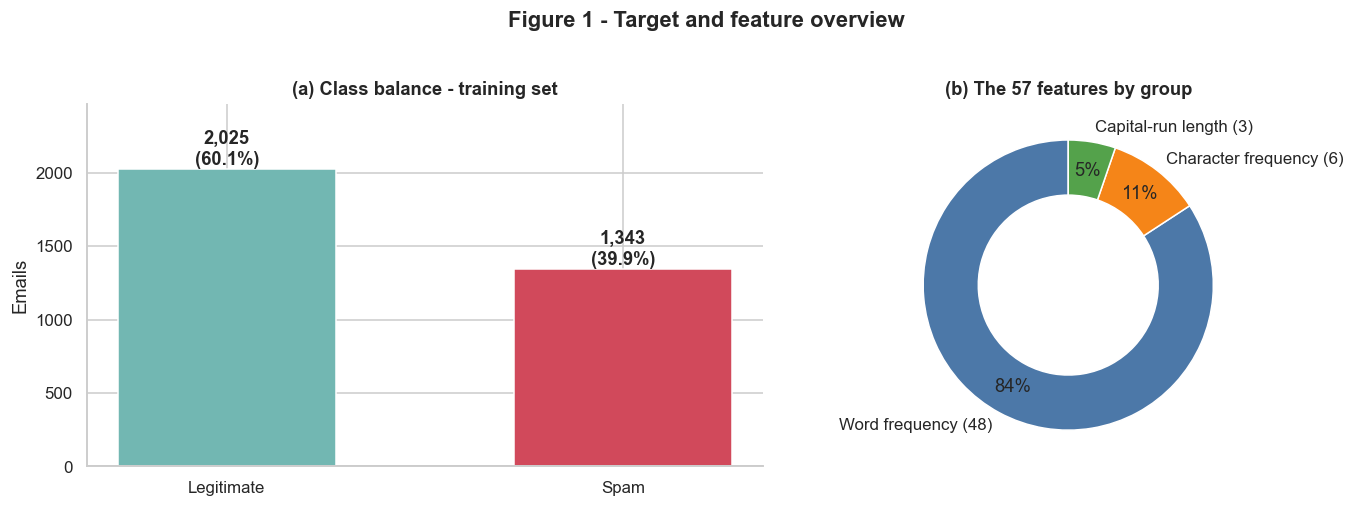

In [5]:
train_eda = X_train.copy()
train_eda["label"] = y_train.map(CLASS_LABELS)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1.2, 1]})

# (a) class balance
counts = train_eda["label"].value_counts().reindex(["Legitimate", "Spam"])
bars = axes[0].bar(counts.index, counts.values,
                   color=[CLASS_COLORS[c] for c in counts.index], width=0.55)
for b, v in zip(bars, counts.values):
    axes[0].text(b.get_x() + b.get_width() / 2, v + 30,
                 f"{v:,}\n({v / counts.sum():.1%})", ha="center", fontweight="bold")
axes[0].set_ylim(0, counts.max() * 1.22)
axes[0].set_title("(a) Class balance - training set")
axes[0].set_ylabel("Emails")

# (b) feature groups
group_counts = pd.Series([feature_group(f) for f in FEATURES]).value_counts()
labels = {"word": "Word frequency (48)", "char": "Character frequency (6)",
          "capital": "Capital-run length (3)"}
axes[1].pie(group_counts.values, labels=[labels[g] for g in group_counts.index],
            colors=[GROUP_COLORS[g] for g in group_counts.index],
            startangle=90, wedgeprops=dict(width=0.38, edgecolor="white"),
            autopct="%1.0f%%", pctdistance=0.8)
axes[1].set_title("(b) The 57 features by group")

plt.suptitle("Figure 1 - Target and feature overview", fontweight="bold", y=1.02)
plt.tight_layout(); save_fig(fig, "fig01_overview"); plt.show()

### Sparsity and skewness

> **What this shows:** (a) for each feature, the share of emails where it is exactly zero; (b) how lopsided (skewed) each feature is, before and after a log transform.
>
> **How to read it:** In (a), taller bars mean the feature is zero for more emails. In (b), each dot is a feature. Dots far below the dashed line became much less skewed after `log1p`.
>
> **Why it matters:** Most features are mostly zeros with a few huge values. Models based on distances (KNN), margins (SVM) or bell-curve assumptions (Naive Bayes) are thrown off by such extreme values, so we transform the data before training.

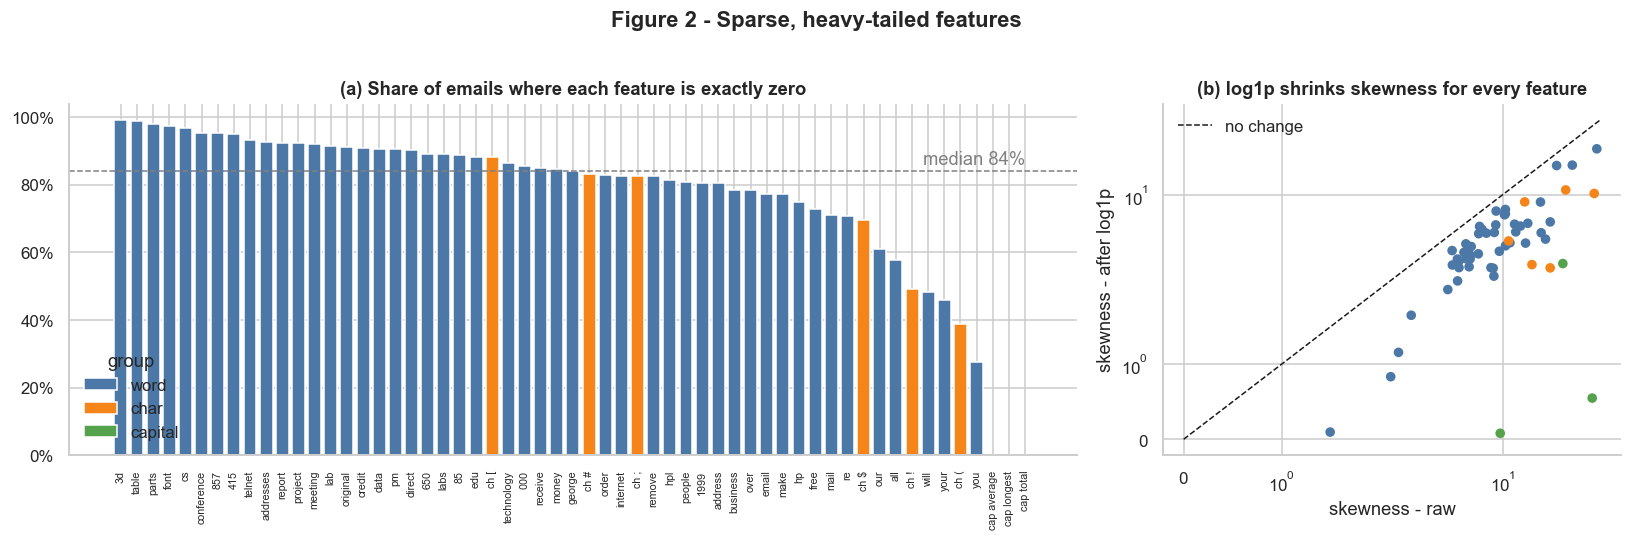

Median share of zeros per feature: 84.0%
Median skewness: raw = 9.1, after log1p = 4.2


In [6]:
zero_pct = (X_train == 0).mean().sort_values(ascending=False) * 100
skew_raw = X_train.skew()
skew_log = np.log1p(X_train).skew()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [2.2, 1]})

axes[0].bar(range(len(zero_pct)), zero_pct.values,
            color=[GROUP_COLORS[feature_group(f)] for f in zero_pct.index])
axes[0].set_xticks(range(len(zero_pct)))
axes[0].set_xticklabels(zero_pct.index.str.replace("word_freq_", "").str.replace("char_freq_", "ch ")
                        .str.replace("capital_run_length_", "cap "), rotation=90, fontsize=7)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter())
axes[0].axhline(zero_pct.median(), ls="--", c="grey", lw=1)
axes[0].text(len(zero_pct) - 1, zero_pct.median() + 2, f"median {zero_pct.median():.0f}%",
             ha="right", color="grey")
axes[0].set_title("(a) Share of emails where each feature is exactly zero")
for g, c in GROUP_COLORS.items():
    axes[0].bar(0, 0, color=c, label=g)
axes[0].legend(title="group", loc="lower left")

axes[1].scatter(skew_raw, skew_log, c=[GROUP_COLORS[feature_group(f)] for f in FEATURES], s=28)
lim = max(skew_raw.max(), 1) * 1.05
axes[1].plot([0, lim], [0, lim], "k--", lw=1, label="no change")
axes[1].set_xscale("symlog"); axes[1].set_yscale("symlog")
axes[1].set_xlabel("skewness - raw"); axes[1].set_ylabel("skewness - after log1p")
axes[1].set_title("(b) log1p shrinks skewness for every feature")
axes[1].legend(loc="upper left")

plt.suptitle("Figure 2 - Sparse, heavy-tailed features", fontweight="bold", y=1.02)
plt.tight_layout(); save_fig(fig, "fig02_sparsity_skew"); plt.show()

print(f"Median share of zeros per feature: {zero_pct.median():.1f}%")
print(f"Median skewness: raw = {skew_raw.median():.1f}, after log1p = {skew_log.median():.1f}")

### Which features separate spam from legitimate email?

> **What this shows:** the 20 features whose average value differs most between spam and legitimate email.
>
> **How to read it:** A red bar to the right means the feature is higher in spam. A teal bar to the left means it is higher in legitimate email. Longer bars are stronger signals.
>
> **Why it matters:** It shows what the models can learn from, and gives a sanity check: words like `free`, `$` and `remove` should point to spam.

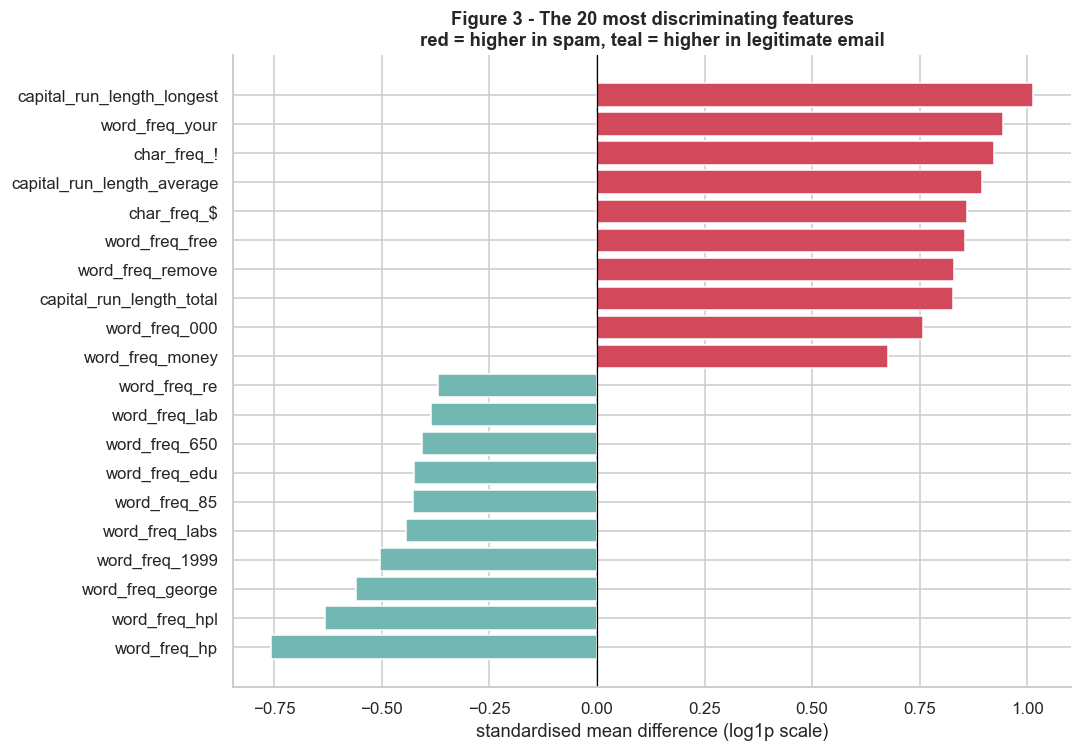

In [7]:
X_log = np.log1p(X_train)
smd = ((X_log[y_train == 1].mean() - X_log[y_train == 0].mean()) / X_log.std()).sort_values()
top_smd = pd.concat([smd.head(10), smd.tail(10)])

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top_smd.index, top_smd.values,
        color=[CLASS_COLORS["Spam"] if v > 0 else CLASS_COLORS["Legitimate"] for v in top_smd.values])
ax.axvline(0, c="black", lw=0.8)
ax.set_xlabel("standardised mean difference (log1p scale)")
ax.set_title("Figure 3 - The 20 most discriminating features\n"
             "red = higher in spam, teal = higher in legitimate email")
plt.tight_layout(); save_fig(fig, "fig03_discriminating_features"); plt.show()

### The six strongest features by class

> **What this shows:** the value distribution of the six most discriminating features, side by side for each class.
>
> **How to read it:** Each box covers the middle 50% of emails, and the line inside is the median. If the red and teal boxes sit at different heights, that feature separates the classes well.
>
> **Why it matters:** It confirms visually that the strongest features genuinely differ between spam and legitimate email.

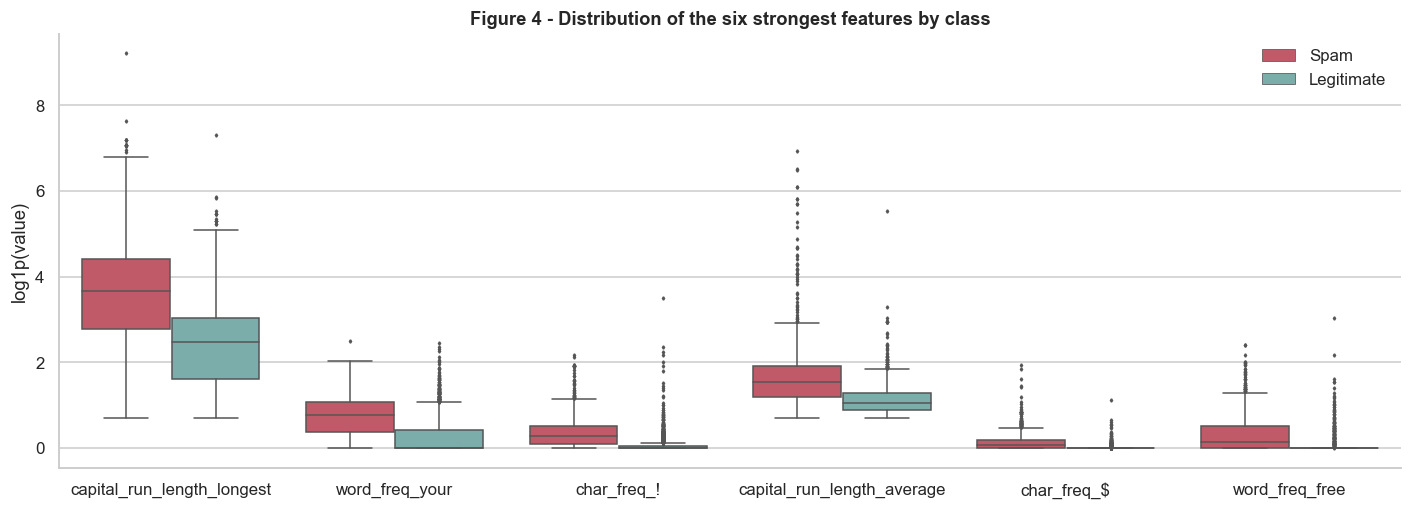

In [8]:
top6 = smd.abs().sort_values(ascending=False).head(6).index.tolist()
long = X_log[top6].assign(label=y_train.map(CLASS_LABELS).values).melt(id_vars="label")

fig, ax = plt.subplots(figsize=(13, 4.8))
sns.boxplot(data=long, x="variable", y="value", hue="label", palette=CLASS_COLORS,
            fliersize=1.5, linewidth=1, ax=ax)
ax.set_xlabel(""); ax.set_ylabel("log1p(value)")
ax.set_title("Figure 4 - Distribution of the six strongest features by class")
ax.legend(title="")
plt.tight_layout(); save_fig(fig, "fig04_top_feature_boxplots"); plt.show()

### Correlation between features

> **What this shows:** pairs of features that tend to rise and fall together.
>
> **How to read it:** +1 (dark red) means two features always move together. 0 means unrelated. The table lists the 10 most correlated pairs.
>
> **Why it matters:** Naive Bayes assumes every feature is independent. Highly correlated features break that assumption, because the model counts the same evidence twice. This helps explain why Naive Bayes struggles here.

,feature A,feature B,correlation
0,word_freq_857,word_freq_415,0.994
1,word_freq_857,word_freq_direct,0.837
2,word_freq_415,word_freq_direct,0.833
3,word_freq_857,word_freq_technology,0.699
4,word_freq_415,word_freq_technology,0.695
5,word_freq_telnet,word_freq_857,0.666
6,word_freq_technology,word_freq_direct,0.664
7,word_freq_labs,word_freq_technology,0.662
8,word_freq_telnet,word_freq_415,0.662
9,word_freq_telnet,word_freq_technology,0.656


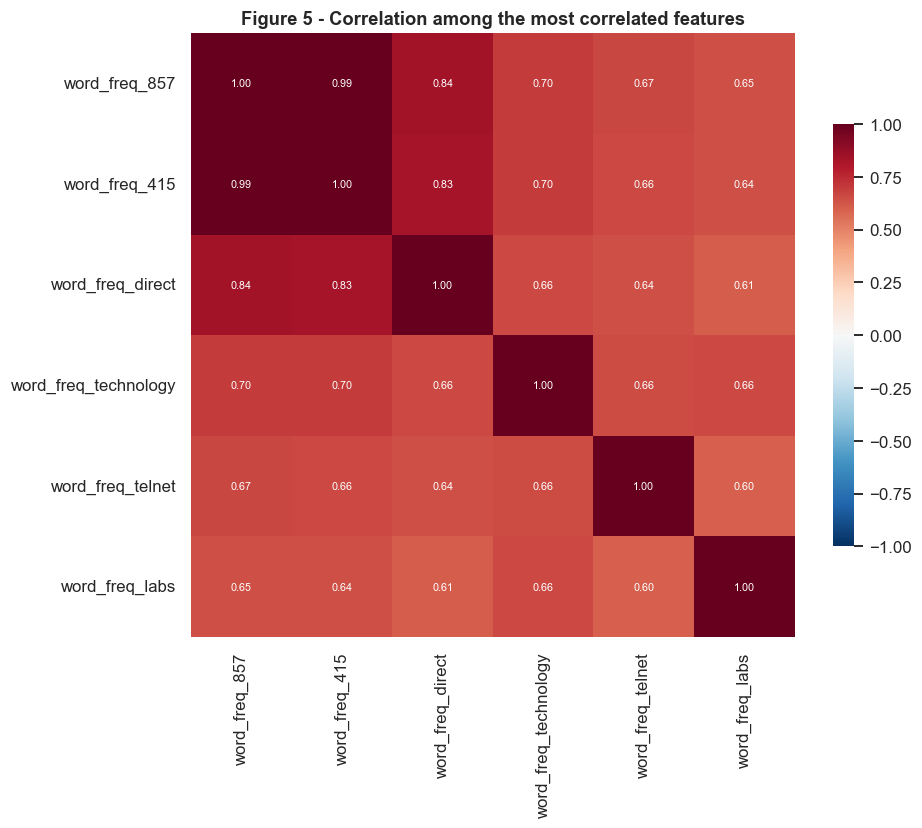

In [9]:
corr = X_train.corr()
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
             .stack().rename("correlation").reset_index()
             .rename(columns={"level_0": "feature A", "level_1": "feature B"}))
pairs["|r|"] = pairs["correlation"].abs()
top_pairs = pairs.sort_values("|r|", ascending=False).head(10).reset_index(drop=True)
display(top_pairs.drop(columns="|r|").round(3))

focus = pd.unique(top_pairs[["feature A", "feature B"]].values.ravel())
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr.loc[focus, focus], cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 7}, square=True,
            cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Figure 5 - Correlation among the most correlated features")
plt.tight_layout(); save_fig(fig, "fig05_correlation"); plt.show()

## 5. Preprocessing pipeline

| Step | Why |
|---|---|
| `log1p` | Compresses the long right tails seen in Figure 2. It is safe because every value is ≥ 0. |
| `StandardScaler` | Gives every feature mean 0 and standard deviation 1. KNN distances, SVM margins and Logistic Regression regularisation all depend on feature scale. |

Both steps are placed **inside each model's `Pipeline`**. This has two benefits. During cross-validation, the scaler is fitted only on the training folds of each split, so nothing leaks from the validation fold. And the saved `.pkl` file contains the full preprocessing, so the Streamlit app just passes in the raw 57 columns.

The **Decision Tree** uses raw features, because a tree splits on thresholds and is unaffected by monotonic transforms or scaling.

> **What this shows:** one feature (`capital_run_length_total`) before and after the `log1p` transform, split by class.
>
> **How to read it:** On the left, almost everything is squashed against zero. On the right, two separate humps appear, one for each class.
>
> **Why it matters:** After the transform the classes are visibly easier to tell apart, which is exactly what helps KNN, SVM and Logistic Regression.

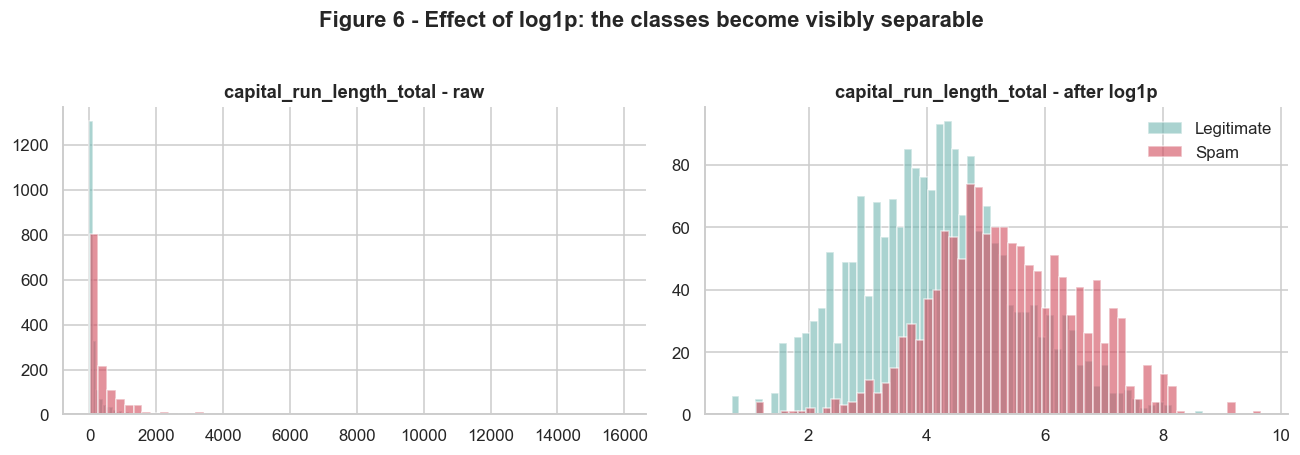

In [10]:
def make_preprocessor():
    return [
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("scale", StandardScaler()),
    ]

cap = "capital_run_length_total"
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for lbl, grp in train_eda.groupby("label"):
    axes[0].hist(grp[cap], bins=60, alpha=0.6, color=CLASS_COLORS[lbl], label=lbl)
    axes[1].hist(np.log1p(grp[cap]), bins=60, alpha=0.6, color=CLASS_COLORS[lbl], label=lbl)
axes[0].set_title(f"{cap} - raw"); axes[1].set_title(f"{cap} - after log1p")
axes[1].legend()
plt.suptitle("Figure 6 - Effect of log1p: the classes become visibly separable",
             fontweight="bold", y=1.03)
plt.tight_layout(); save_fig(fig, "fig06_log_transform"); plt.show()

## 6. Models and hyperparameter search

All tuning uses **5-fold stratified cross-validation on the training set**, scored on F1 (spam is the positive class). The test set is not touched.

| Model | Search space | Notes |
|---|---|---|
| Logistic Regression | `C` ∈ {0.01, 0.1, 1, 10} | `C` is the inverse of regularisation strength |
| Decision Tree | depth, minimum leaf size, split criterion | raw features |
| KNN | k ∈ {3…15}, uniform or distance weights | |
| Gaussian NB | none | no meaningful hyperparameters |
| SVM (RBF) | `C` ∈ {0.5, 1, 5, 10}, `gamma` ∈ {scale, 0.01} | `probability=True` so the model can output scores for AUC |

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    "Logistic Regression": GridSearchCV(
        Pipeline(make_preprocessor() + [
            ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))]),
        param_grid={"model__C": [0.01, 0.1, 1, 10]},
        scoring="f1", cv=cv, n_jobs=-1,
    ),
    "Decision Tree": GridSearchCV(
        Pipeline([("model", DecisionTreeClassifier(random_state=RANDOM_STATE))]),
        param_grid={
            "model__max_depth": [4, 6, 8, 10, 15, None],
            "model__min_samples_leaf": [1, 3, 5, 10],
            "model__criterion": ["gini", "entropy"],
        },
        scoring="f1", cv=cv, n_jobs=-1,
    ),
    "KNN": GridSearchCV(
        Pipeline(make_preprocessor() + [("model", KNeighborsClassifier())]),
        param_grid={
            "model__n_neighbors": [3, 5, 7, 9, 11, 15],
            "model__weights": ["uniform", "distance"],
        },
        scoring="f1", cv=cv, n_jobs=-1,
    ),
    "Naive Bayes": Pipeline(make_preprocessor() + [("model", GaussianNB())]),
    "SVM": GridSearchCV(
        Pipeline(make_preprocessor() + [
            ("model", SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE))]),
        param_grid={"model__C": [0.5, 1, 5, 10], "model__gamma": ["scale", 0.01]},
        scoring="f1", cv=cv, n_jobs=-1,
    ),
}

## 7. Training

In [12]:
trained, search_info = {}, {}

for name, estimator in models.items():
    start = time.time()
    estimator.fit(X_train, y_train)
    total = time.time() - start

    if isinstance(estimator, GridSearchCV):
        trained[name] = estimator.best_estimator_
        search_info[name] = {
            "Best parameters": {k.replace("model__", ""): v for k, v in estimator.best_params_.items()},
            "CV F1 (best)": round(estimator.best_score_, 4),
            "Candidates tried": len(estimator.cv_results_["params"]),
            "Search time (s)": round(total, 1),
            "Final fit time (s)": round(estimator.refit_time_, 3),
        }
    else:
        trained[name] = estimator
        search_info[name] = {"Best parameters": "-", "CV F1 (best)": np.nan,
                             "Candidates tried": 1, "Search time (s)": round(total, 1),
                             "Final fit time (s)": round(total, 3)}
    print(f"[done] {name:20s} {total:6.1f} s")

search_df = pd.DataFrame(search_info).T
display(search_df)

[done] Logistic Regression    17.3 s
[done] Decision Tree           3.6 s
[done] KNN                     2.5 s
[done] Naive Bayes             0.0 s
[done] SVM                    18.1 s


,Best parameters,CV F1 (best),Candidates tried,Search time (s),Final fit time (s)
Logistic Regression,{'C': 0.1},0.9154,4,17.3,0.056
Decision Tree,"{'criterion': 'entropy', 'max_depth': None, 'm...",0.8958,48,3.6,0.129
KNN,"{'n_neighbors': 9, 'weights': 'distance'}",0.9141,12,2.5,0.022
Naive Bayes,-,NaN,1,0.0,0.026
SVM,"{'C': 5, 'gamma': 'scale'}",0.93,8,18.1,1.593


## 7b. Fixing the Decision Tree's overfitting

The grid search above chose an **unlimited tree** (`max_depth=None`, `min_samples_leaf=1`). A tree like that keeps splitting until every leaf is pure, so it ends up memorising the training emails, noise and all. This is **overfitting**.

**The fix: cost-complexity pruning.** We grow the full tree, then cut back the branches that add the least value. The setting `ccp_alpha` controls how hard we cut. At 0 nothing is cut, and larger values give a smaller, simpler tree.

**How the amount of pruning is chosen, without touching the test set.** We try about 40 values of `ccp_alpha`, each with 5-fold cross-validation on the training data. Then we apply the **one-standard-error rule**, the standard rule for pruning trees: pick the *simplest* tree whose CV score is within one standard error of the best score. A smaller tree that scores just as well is more trustworthy.

In [13]:
dt_search = models["Decision Tree"]
dt_unpruned = trained["Decision Tree"]
base_params = {k.replace("model__", ""): v for k, v in dt_search.best_params_.items()}
base_tree = DecisionTreeClassifier(random_state=RANDOM_STATE, **base_params)

# All the alpha values at which the tree would lose a branch
path = clone(base_tree).cost_complexity_pruning_path(X_train, y_train)
alphas = np.unique(path.ccp_alphas[:-1])          # the last alpha leaves a single node, so skip it
if len(alphas) > 40:                               # keep ~40 evenly spread values so this runs quickly
    alphas = np.unique(np.quantile(alphas, np.linspace(0, 1, 40)))

rows = []
for a in alphas:
    pipe = Pipeline([("model", clone(base_tree).set_params(ccp_alpha=a))])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring="f1",
                         return_train_score=True, n_jobs=-1)
    full = clone(base_tree).set_params(ccp_alpha=a).fit(X_train, y_train)
    rows.append({"ccp_alpha": a, "leaves": full.get_n_leaves(), "depth": full.get_depth(),
                 "train_f1": res["train_score"].mean(),
                 "cv_f1": res["test_score"].mean(), "cv_std": res["test_score"].std()})
prune_df = pd.DataFrame(rows)

# One-standard-error rule: simplest tree within 1 SE of the best CV score
best_i = prune_df["cv_f1"].idxmax()
se = prune_df.loc[best_i, "cv_std"] / np.sqrt(cv.get_n_splits())
threshold = prune_df.loc[best_i, "cv_f1"] - se
chosen = prune_df[prune_df["cv_f1"] >= threshold].sort_values("ccp_alpha").iloc[-1]
chosen_alpha = float(chosen["ccp_alpha"])

start = time.time()
dt_pruned = Pipeline([("model", clone(base_tree).set_params(ccp_alpha=chosen_alpha))]).fit(X_train, y_train)
dt_fit_time = time.time() - start
trained["Decision Tree"] = dt_pruned       # the pruned tree becomes our final Decision Tree

unpruned_row = prune_df.iloc[0]
before_after = pd.DataFrame({
    "Before pruning": {"ccp_alpha": 0.0, "Depth": int(unpruned_row["depth"]),
                       "Leaves": int(unpruned_row["leaves"]),
                       "Train F1": unpruned_row["train_f1"], "CV F1": unpruned_row["cv_f1"]},
    "After pruning":  {"ccp_alpha": chosen_alpha, "Depth": int(chosen["depth"]),
                       "Leaves": int(chosen["leaves"]),
                       "Train F1": chosen["train_f1"], "CV F1": chosen["cv_f1"]},
}).T
before_after["Train - CV gap (pp)"] = (before_after["Train F1"] - before_after["CV F1"]) * 100
display(before_after.style.format({"ccp_alpha": "{:.5f}", "Depth": "{:.0f}", "Leaves": "{:.0f}",
                                   "Train F1": "{:.4f}", "CV F1": "{:.4f}",
                                   "Train - CV gap (pp)": "{:+.2f}"})
        .set_caption("Decision Tree before vs after pruning (training data only)"))

# Update the search summary so later tables show the final (pruned) tree
search_info["Decision Tree"]["Best parameters"] = {**base_params, "ccp_alpha": round(chosen_alpha, 5)}
search_info["Decision Tree"]["CV F1 (best)"] = round(float(chosen["cv_f1"]), 4)
search_info["Decision Tree"]["Final fit time (s)"] = round(dt_fit_time, 3)
search_df = pd.DataFrame(search_info).T

,ccp_alpha,Depth,Leaves,Train F1,CV F1,Train - CV gap (pp)
Before pruning,0.00000,27,194,0.9992,0.8958,+10.33
After pruning,0.00283,15,46,0.9439,0.8953,+4.86


> **What this shows:** (a) how the training score and the cross-validation score change as the tree is pruned from very big to very small; (b) the tree before and after pruning.
>
> **How to read it:** In (a), the x-axis is tree size (number of leaves). The dashed line is the score on the training data and the solid line is the score on unseen folds. Where the two lines are far apart, the tree is memorising. The star marks the tree we chose. In (b), shorter grey gaps between the bars mean less overfitting.
>
> **Why it matters:** It shows the overfitting problem and the fix in one picture: we keep the cross-validation score while removing most of the tree.

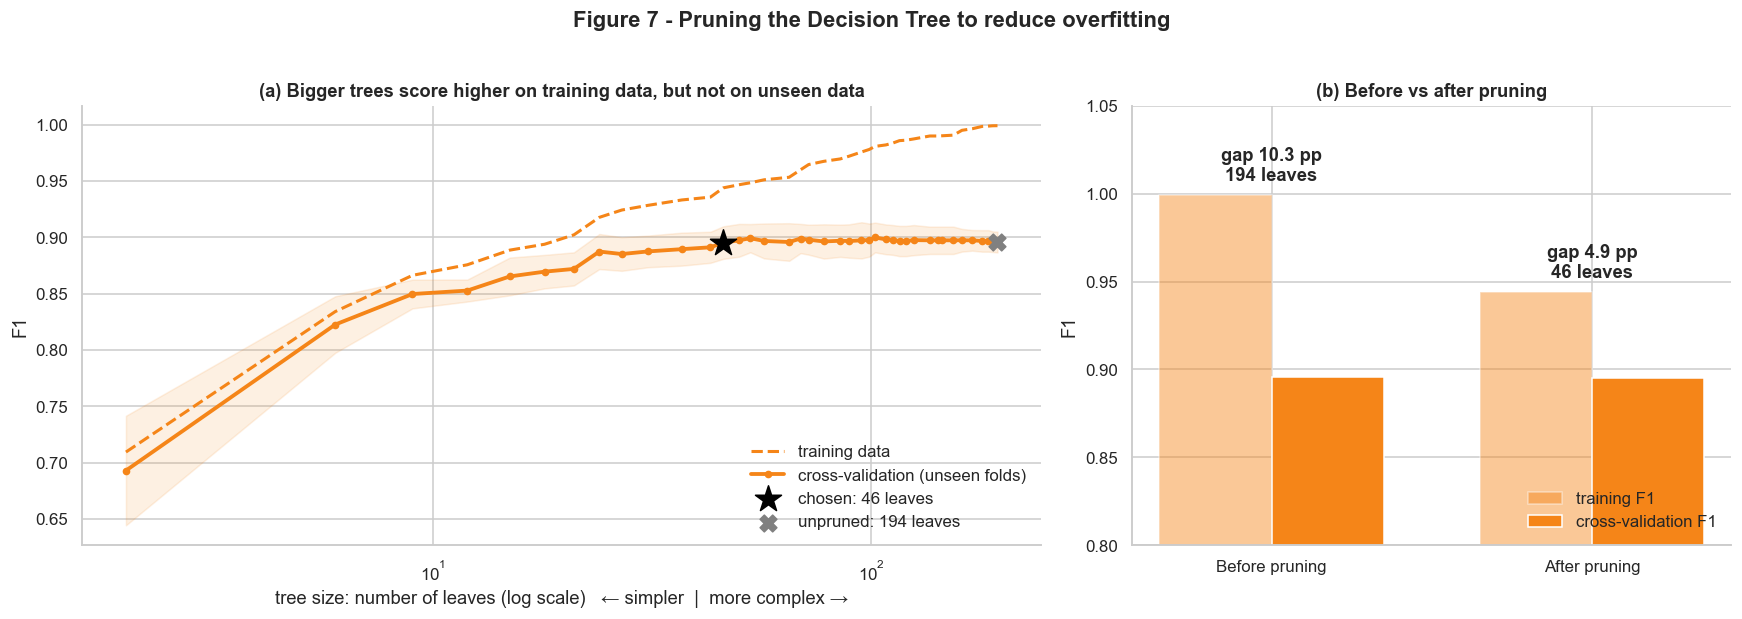

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1.6, 1]})
c = MODEL_COLORS["Decision Tree"]

d = prune_df.sort_values("leaves")
axes[0].plot(d["leaves"], d["train_f1"], "--", color=c, lw=2, label="training data")
axes[0].plot(d["leaves"], d["cv_f1"], "-", color=c, lw=2.5, marker="o", ms=4, label="cross-validation (unseen folds)")
axes[0].fill_between(d["leaves"], d["cv_f1"] - d["cv_std"], d["cv_f1"] + d["cv_std"], color=c, alpha=0.12)
axes[0].scatter(chosen["leaves"], chosen["cv_f1"], s=320, marker="*", color="black", zorder=5,
                label=f"chosen: {int(chosen['leaves'])} leaves")
axes[0].scatter(unpruned_row["leaves"], unpruned_row["cv_f1"], s=120, marker="X", color="grey", zorder=5,
                label=f"unpruned: {int(unpruned_row['leaves'])} leaves")
axes[0].set_xscale("log")
axes[0].set_xlabel("tree size: number of leaves (log scale)   ← simpler  |  more complex →")
axes[0].set_ylabel("F1")
axes[0].set_title("(a) Bigger trees score higher on training data, but not on unseen data")
axes[0].legend(loc="lower right")

labels = ["Before pruning", "After pruning"]
x = np.arange(2); w = 0.35
tr = before_after["Train F1"].values; cvv = before_after["CV F1"].values
axes[1].bar(x - w / 2, tr, w, color=c, alpha=0.45, label="training F1")
axes[1].bar(x + w / 2, cvv, w, color=c, label="cross-validation F1")
for i in range(2):
    axes[1].text(i, max(tr[i], cvv[i]) + 0.008,
                 f"gap {(tr[i] - cvv[i]) * 100:.1f} pp\n{int(before_after['Leaves'].iloc[i])} leaves",
                 ha="center", fontweight="bold")
axes[1].set_xticks(x); axes[1].set_xticklabels(labels)
axes[1].set_ylim(0.8, 1.05); axes[1].set_ylabel("F1")
axes[1].set_title("(b) Before vs after pruning")
axes[1].legend(loc="lower right")

plt.suptitle("Figure 7 - Pruning the Decision Tree to reduce overfitting", fontweight="bold", y=1.02)
plt.tight_layout(); save_fig(fig, "fig07_dt_pruning"); plt.show()

### How stable is each model across the 5 folds?

We re-run 5-fold cross-validation on the training data with each model's **final** setting (including the pruned tree), and keep all five scores, not just the average.

> **What this shows:** the F1 score of each model on each of the 5 cross-validation folds. Each black dot is one fold.
>
> **How to read it:** Higher boxes are better models. Shorter boxes mean the model scores about the same on every fold, which makes it reliable. The `±` in the table is how much the score varies between folds.
>
> **Why it matters:** A model with a high average but big swings is less trustworthy. This check also tells us what range of test score to expect.

,CV Accuracy,CV AUC,CV F1,CV MCC
Model,,,,
Logistic Regression,0.9335 ± 0.0147,0.9772 ± 0.0062,0.9154 ± 0.0185,0.8610 ± 0.0308
Decision Tree,0.9163 ± 0.0121,0.9546 ± 0.0102,0.8953 ± 0.0144,0.8266 ± 0.0241
KNN,0.9320 ± 0.0136,0.9713 ± 0.0070,0.9141 ± 0.0169,0.8580 ± 0.0283
Naive Bayes,0.8299 ± 0.0187,0.9436 ± 0.0114,0.8173 ± 0.0170,0.6881 ± 0.0305
SVM,0.9448 ± 0.0116,0.9785 ± 0.0084,0.9300 ± 0.0145,0.8846 ± 0.0242


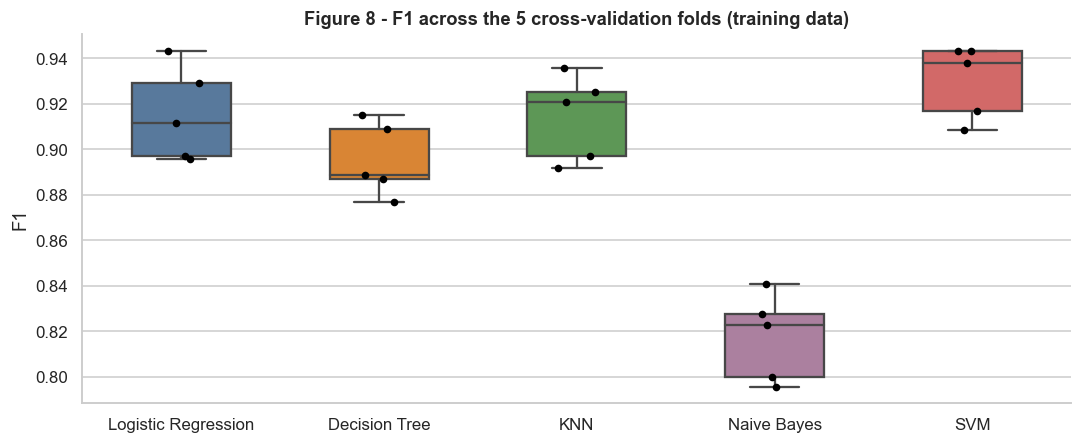

In [15]:
cv_scoring = {"Accuracy": "accuracy", "AUC": "roc_auc", "F1": "f1",
              "MCC": make_scorer(matthews_corrcoef)}
cv_rows, cv_folds, cv_numeric = [], [], {}

for name, m in trained.items():
    res = cross_validate(clone(m), X_train, y_train, cv=cv, scoring=cv_scoring, n_jobs=-1)
    row = {"Model": name}
    for k in cv_scoring:
        s = res[f"test_{k}"]
        row[f"CV {k}"] = f"{s.mean():.4f} ± {s.std():.4f}"
        cv_numeric.setdefault(name, {})[k] = [float(s.mean()), float(s.std())]
        if k == "F1":
            cv_folds += [{"Model": name, "F1": v} for v in s]
    cv_rows.append(row)

cv_table = pd.DataFrame(cv_rows).set_index("Model")
display(cv_table)

cv_folds = pd.DataFrame(cv_folds)
fig, ax = plt.subplots(figsize=(10, 4.2))
sns.boxplot(data=cv_folds, x="Model", y="F1", palette=MODEL_COLORS, width=0.5,
            showfliers=False, ax=ax)
sns.stripplot(data=cv_folds, x="Model", y="F1", color="black", size=5, ax=ax)
ax.set_xlabel(""); ax.set_title("Figure 8 - F1 across the 5 cross-validation folds (training data)")
plt.tight_layout(); save_fig(fig, "fig08_cv_stability"); plt.show()

## 8. Test-set evaluation

All metrics use **spam (1) as the positive class**.

| Metric | What it measures |
|---|---|
| Precision | Of the emails flagged as spam, the share that really are spam. Low precision means legitimate mail is lost. |
| Recall | Of the real spam, the share that was caught. Low recall means spam reaches the inbox. |
| F1 | The harmonic mean of precision and recall |
| AUC | How well the model *ranks* spam above legitimate email, across every possible threshold |
| MCC | A correlation between predictions and truth that uses all four confusion-matrix cells. It is robust to the 60/40 class imbalance. |

> **What this shows:** the final exam result: all six metrics for every model, calculated on the 842 locked-away test emails.
>
> **How to read it:** Within each column, darker green is better and the outlined cell is the best model for that metric. The rank table below gives each model a position from 1 to 5 in every column.
>
> **Why it matters:** This is the comparison table the assignment asks for.

In [16]:
def evaluate(model, X, y):
    y_pred = model.predict(X)
    y_proba = model.predict_proba(X)[:, 1]
    return {
        "Accuracy":  accuracy_score(y, y_pred),
        "AUC":       roc_auc_score(y, y_proba),
        "Precision": precision_score(y, y_pred, zero_division=0),
        "Recall":    recall_score(y, y_pred, zero_division=0),
        "F1":        f1_score(y, y_pred, zero_division=0),
        "MCC":       matthews_corrcoef(y, y_pred),
    }

preds  = {n: m.predict(X_test) for n, m in trained.items()}
probas = {n: m.predict_proba(X_test)[:, 1] for n, m in trained.items()}

results = pd.DataFrame({n: evaluate(m, X_test, y_test) for n, m in trained.items()}).T
results.index.name = "ML Model Name"
results = results.round(4)

# For reporting only: the unpruned tree on the test set (it is NOT used to choose anything)
dt_before_test = evaluate(dt_unpruned, X_test, y_test)
dt_before_pred = dt_unpruned.predict(X_test)

display(results.style
        .format("{:.4f}")
        .background_gradient(cmap="Greens", axis=0)
        .highlight_max(axis=0, props="font-weight:bold; border:2px solid #333;")
        .set_caption("Test-set metrics (best per column outlined)"))

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.9382,0.9809,0.9329,0.9107,0.9217,0.8709
Decision Tree,0.9169,0.9600,0.9105,0.8780,0.8939,0.8260
KNN,0.9311,0.9782,0.9238,0.9018,0.9127,0.8560
Naive Bayes,0.8420,0.9533,0.7344,0.9464,0.8270,0.7046
SVM,0.9525,0.9807,0.9379,0.9435,0.9407,0.9011


In [17]:
ranks = results.rank(ascending=False, method="min").astype(int)
ranks["Mean rank"] = ranks.mean(axis=1).round(2)
ranks = ranks.sort_values("Mean rank")
display(ranks.style.background_gradient(cmap="RdYlGn_r", subset=list(results.columns))
        .format("{:.2f}", subset=["Mean rank"])
        .set_caption("Rank of each model per metric (1 = best)"))

,Accuracy,AUC,Precision,Recall,F1,MCC,Mean rank
ML Model Name,,,,,,,
SVM,1,2,1,2,1,1,1.33
Logistic Regression,2,1,2,3,2,2,2.00
KNN,3,3,3,4,3,3,3.17
Decision Tree,4,4,4,5,4,4,4.17
Naive Bayes,5,5,5,1,5,5,4.33


> **What this shows:** the same test-set scores as the table, drawn as (a) grouped bars and (b) a heatmap.
>
> **How to read it:** In (a), each group is one metric with one bar per model. The y-axis starts at 0.6 so the differences are visible. In (b), darker green means a higher score.
>
> **Why it matters:** You can see at a glance which model leads overall, and the Naive Bayes pattern of high recall with low precision.

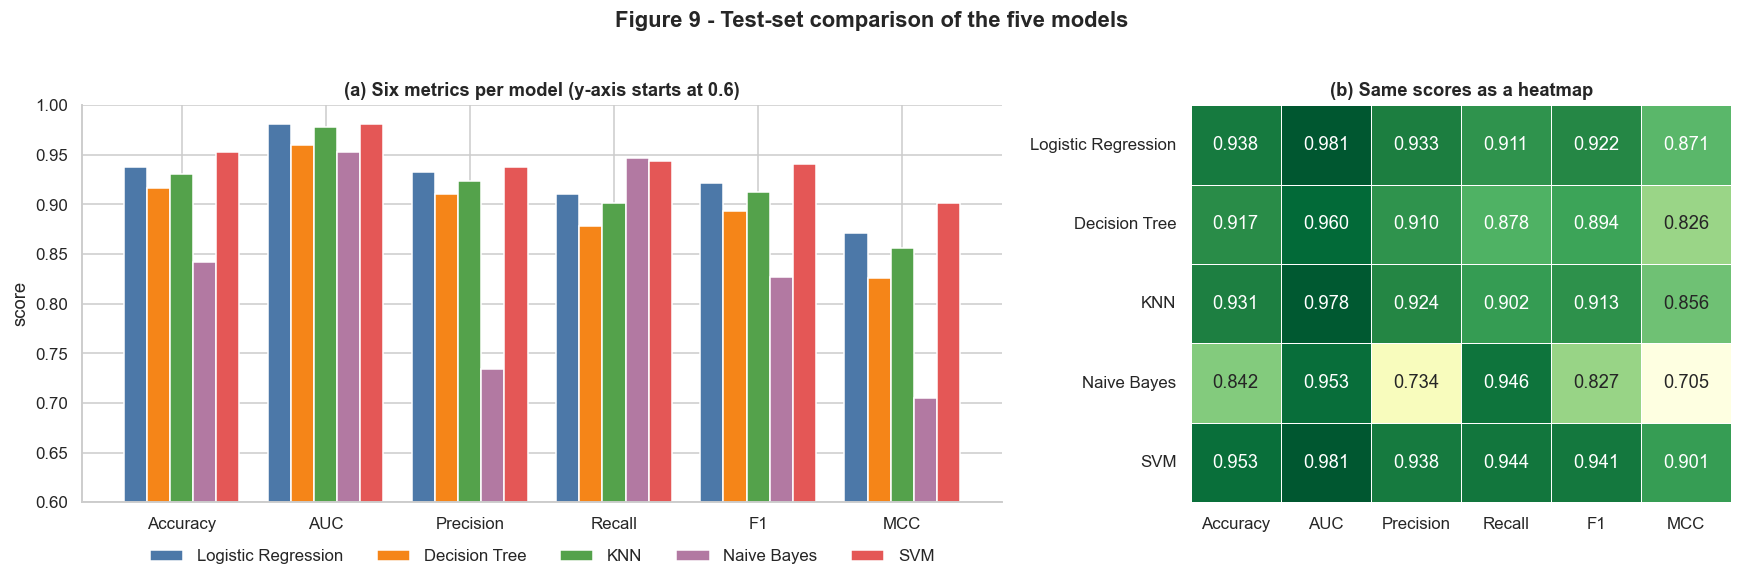

In [18]:
metric_names = list(results.columns)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2), gridspec_kw={"width_ratios": [1.7, 1]})

# (a) grouped bars
w = 0.16
x = np.arange(len(metric_names))
for i, (name, row) in enumerate(results.iterrows()):
    axes[0].bar(x + (i - 2) * w, row.values, w, label=name, color=MODEL_COLORS[name])
axes[0].set_xticks(x); axes[0].set_xticklabels(metric_names)
axes[0].set_ylim(0.6, 1.0)
axes[0].set_ylabel("score")
axes[0].set_title("(a) Six metrics per model (y-axis starts at 0.6)")
axes[0].legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.08))

# (b) heatmap
sns.heatmap(results, annot=True, fmt=".3f", cmap="YlGn", cbar=False,
            linewidths=0.5, ax=axes[1], vmin=0.7, vmax=1)
axes[1].set_title("(b) Same scores as a heatmap"); axes[1].set_ylabel("")

plt.suptitle("Figure 9 - Test-set comparison of the five models", fontweight="bold", y=1.02)
plt.tight_layout(); save_fig(fig, "fig09_metric_comparison"); plt.show()

### Confusion matrices

> **What this shows:** for each model, how the 842 test emails were sorted: what each email really was vs what the model said.
>
> **How to read it:** Each matrix has four boxes. **Top-left**: good emails correctly kept. **Top-right**: good emails wrongly sent to spam (false positives, the worst mistake for a user). **Bottom-left**: spam that slipped into the inbox (false negatives). **Bottom-right**: spam correctly caught. The diagonal boxes are correct; the other two are mistakes. The title shows the total number of errors.
>
> **Why it matters:** Every metric in the table above is calculated from these four numbers, and the matrices show *which kind* of mistake each model makes.

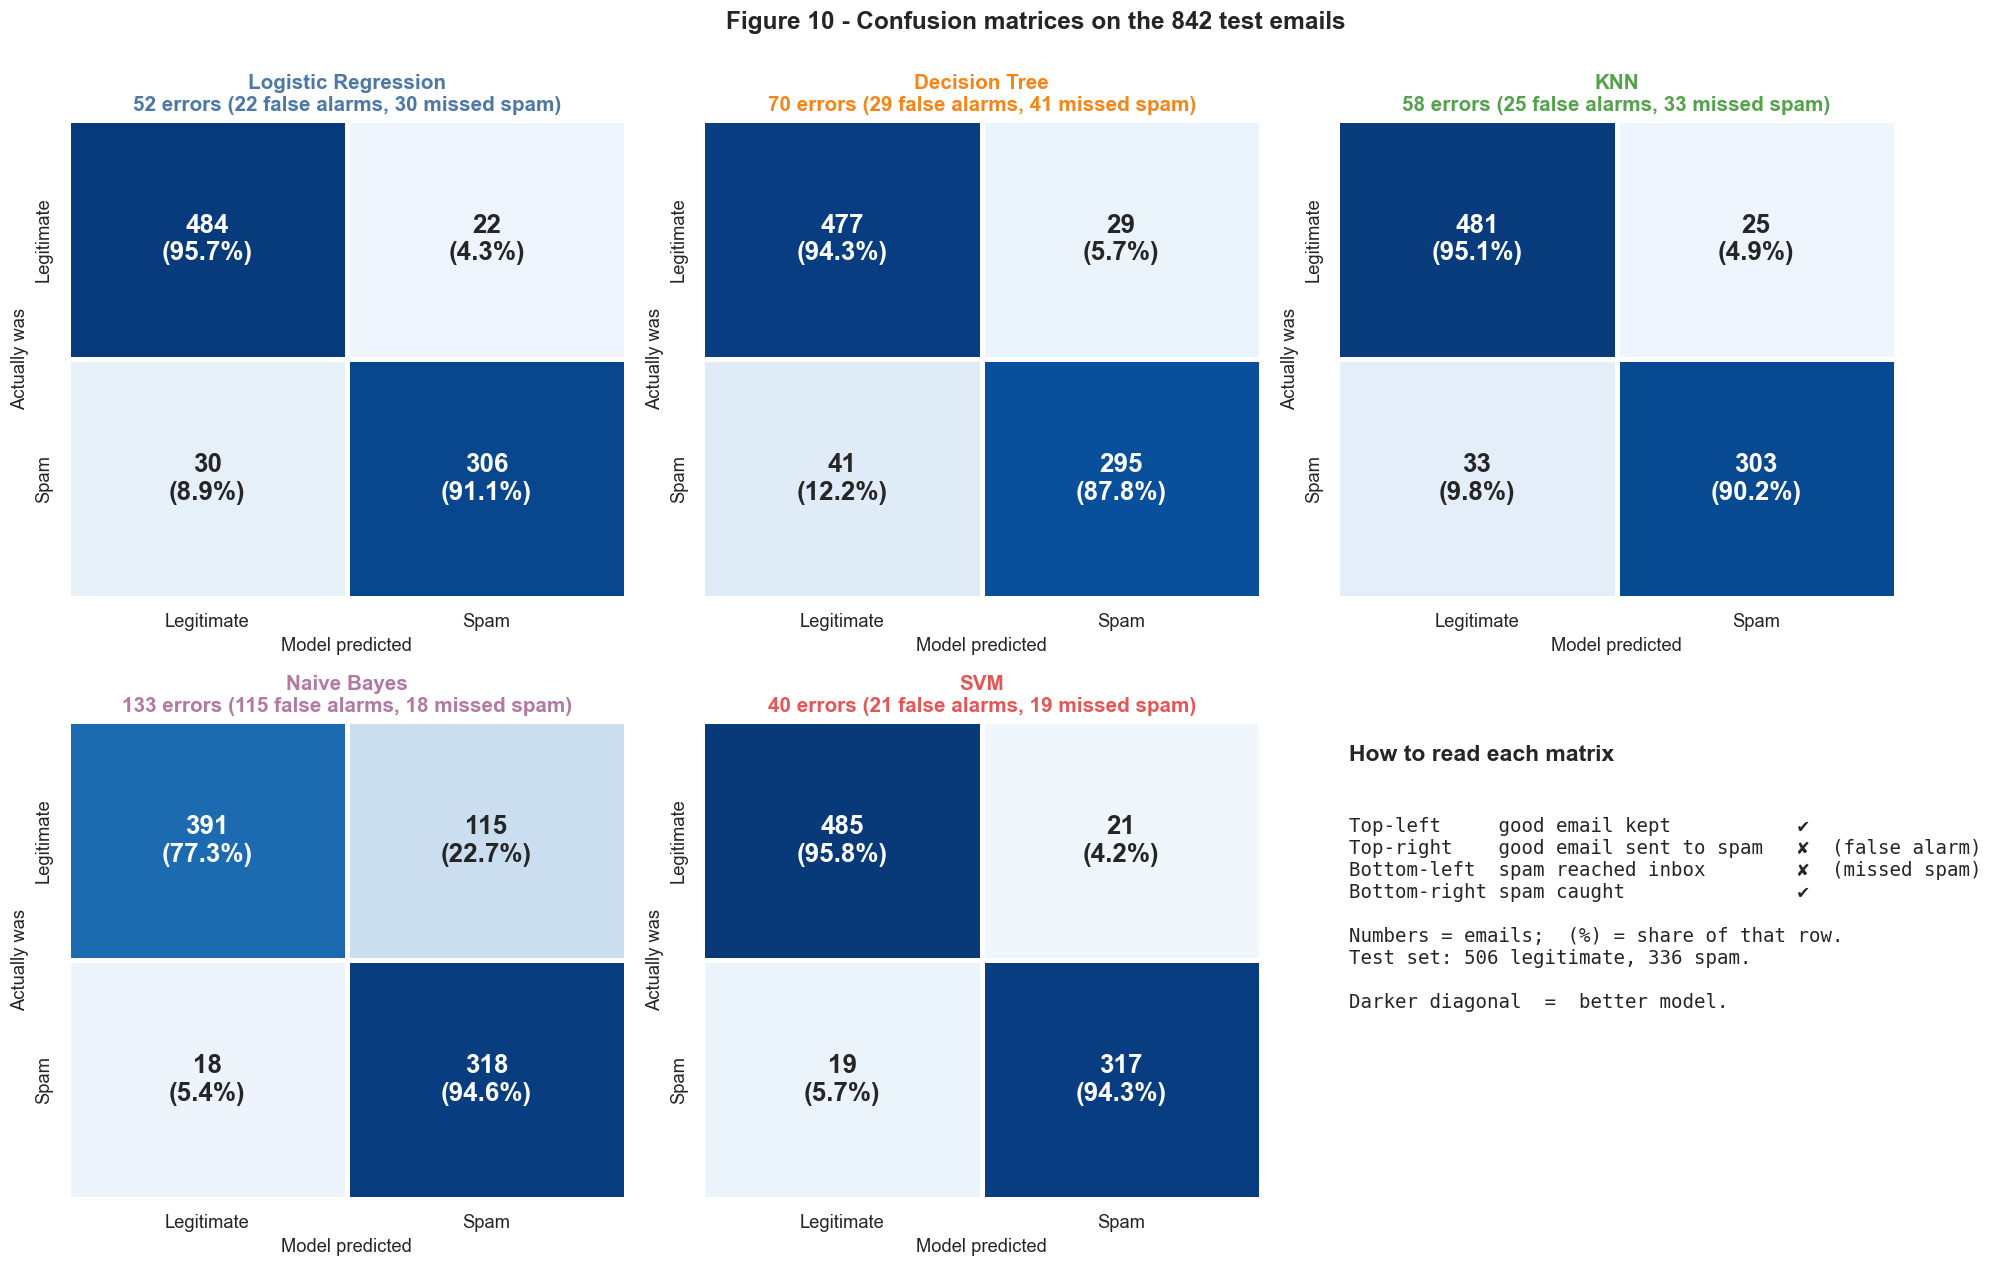

,Good emails kept,False alarms (good -> spam),Missed spam (spam -> inbox),Spam caught,Total errors
Logistic Regression,484,22,30,306,52
Decision Tree,477,29,41,295,70
KNN,481,25,33,303,58
Naive Bayes,391,115,18,318,133
SVM,485,21,19,317,40


In [19]:
fig, axes = plt.subplots(2, 3, figsize=(19, 11.5))
axes = axes.ravel()
cms = {}
for ax, name in zip(axes, trained):
    cm = confusion_matrix(y_test, preds[name], labels=[0, 1])
    cms[name] = cm
    pct = cm / cm.sum(axis=1, keepdims=True)
    annot = np.array([[f"{cm[i, j]}\n({pct[i, j]:.1%})" for j in range(2)] for i in range(2)])
    sns.heatmap(pct, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False,
                xticklabels=["Legitimate", "Spam"], yticklabels=["Legitimate", "Spam"],
                annot_kws={"size": 17, "weight": "bold"}, linewidths=2, linecolor="white", ax=ax)
    tn, fp, fn, tp = cm.ravel()
    ax.set_title(f"{name}\n{fp + fn} errors ({fp} false alarms, {fn} missed spam)",
                 color=MODEL_COLORS[name], fontsize=13.5, fontweight="bold")
    ax.set_xlabel("Model predicted", fontsize=12); ax.set_ylabel("Actually was", fontsize=12)
    ax.tick_params(labelsize=12)

# 6th panel: a reading guide
guide = axes[5]
guide.axis("off")
guide.text(0.02, 0.95, "How to read each matrix", fontsize=15, fontweight="bold", va="top")
guide.text(0.02, 0.80,
           "Top-left     good email kept           ✔\n"
           "Top-right    good email sent to spam   ✘  (false alarm)\n"
           "Bottom-left  spam reached inbox        ✘  (missed spam)\n"
           "Bottom-right spam caught               ✔\n\n"
           "Numbers = emails;  (%) = share of that row.\n"
           f"Test set: {int((y_test == 0).sum())} legitimate, {int(y_test.sum())} spam.\n\n"
           "Darker diagonal  =  better model.",
           fontsize=12.5, va="top", family="monospace")

plt.suptitle(f"Figure 10 - Confusion matrices on the {len(y_test)} test emails",
             fontweight="bold", fontsize=16, y=1.0)
plt.tight_layout(); save_fig(fig, "fig10_confusion_matrices"); plt.show()

err_table = pd.DataFrame({
    n: {"Good emails kept": c[0, 0], "False alarms (good -> spam)": c[0, 1],
        "Missed spam (spam -> inbox)": c[1, 0], "Spam caught": c[1, 1],
        "Total errors": c[0, 1] + c[1, 0]} for n, c in cms.items()}).T
display(err_table.style.background_gradient(cmap="Reds", subset=["False alarms (good -> spam)",
                                                                  "Missed spam (spam -> inbox)",
                                                                  "Total errors"]))

### Per-class report card (classification report)

The main table scores the models from the **spam** point of view only. A classification report scores **both classes separately**: how good the model is at handling legitimate email, and how good it is at handling spam.

- **Precision for a class**: when the model *says* this class, how often is it right?
- **Recall for a class**: of all emails that really *are* this class, how many did the model get?
- **F1 for a class**: a single balance of the two.

Below is the same information as scikit-learn's `classification_report`, laid out as one table, followed by a plain-English summary for each model.

In [20]:
rep_rows = {}
for name in trained:
    r = classification_report(y_test, preds[name], output_dict=True, zero_division=0)
    rep_rows[name] = {
        ("Legitimate emails", "Precision"): r["0"]["precision"],
        ("Legitimate emails", "Recall"):    r["0"]["recall"],
        ("Legitimate emails", "F1"):        r["0"]["f1-score"],
        ("Spam emails", "Precision"):       r["1"]["precision"],
        ("Spam emails", "Recall"):          r["1"]["recall"],
        ("Spam emails", "F1"):              r["1"]["f1-score"],
        ("Overall", "Accuracy"):            r["accuracy"],
        ("Overall", "Macro F1"):            r["macro avg"]["f1-score"],
    }
report_card = pd.DataFrame(rep_rows).T
report_card.columns = pd.MultiIndex.from_tuples(report_card.columns)
display(report_card.style.format("{:.4f}").background_gradient(cmap="Greens", axis=0)
        .set_caption(f"Per-class scores on the test set "
                     f"({int((y_test == 0).sum())} legitimate, {int(y_test.sum())} spam)"))

lines = []
for name, c in cms.items():
    tn, fp, fn, tp = c.ravel()
    lines.append(
        f"- **{name}**: kept **{tn} of {tn + fp}** good emails ({tn / (tn + fp):.1%}) and caught "
        f"**{tp} of {tp + fn}** spam ({tp / (tp + fn):.1%}). When it says *spam* it is right "
        f"{tp / (tp + fp):.1%} of the time; when it says *legitimate* it is right {tn / (tn + fn):.1%} of the time.")
display(Markdown("\n".join(lines)))

- **Logistic Regression**: kept **484 of 506** good emails (95.7%) and caught **306 of 336** spam (91.1%). When it says *spam* it is right 93.3% of the time; when it says *legitimate* it is right 94.2% of the time.
- **Decision Tree**: kept **477 of 506** good emails (94.3%) and caught **295 of 336** spam (87.8%). When it says *spam* it is right 91.0% of the time; when it says *legitimate* it is right 92.1% of the time.
- **KNN**: kept **481 of 506** good emails (95.1%) and caught **303 of 336** spam (90.2%). When it says *spam* it is right 92.4% of the time; when it says *legitimate* it is right 93.6% of the time.
- **Naive Bayes**: kept **391 of 506** good emails (77.3%) and caught **318 of 336** spam (94.6%). When it says *spam* it is right 73.4% of the time; when it says *legitimate* it is right 95.6% of the time.
- **SVM**: kept **485 of 506** good emails (95.8%) and caught **317 of 336** spam (94.3%). When it says *spam* it is right 93.8% of the time; when it says *legitimate* it is right 96.2% of the time.

### ROC and precision-recall curves

> **What this shows:** how well each model can rank emails from "most likely spam" to "least likely spam", across every possible cut-off, not just the default one.
>
> **How to read it:** (a) ROC: a curve that hugs the top-left corner is better. The dashed diagonal is random guessing. AUC is the area under the curve, where 1.0 is perfect and 0.5 is random. The inset zooms in on the top-left corner. (b) Precision-recall: a curve that stays high towards the right is better. It shows how much precision you lose as you try to catch more spam.
>
> **Why it matters:** A model can rank emails well (high AUC) but still make poor decisions at the default cut-off. Comparing these curves with the confusion matrices shows which models have that problem.

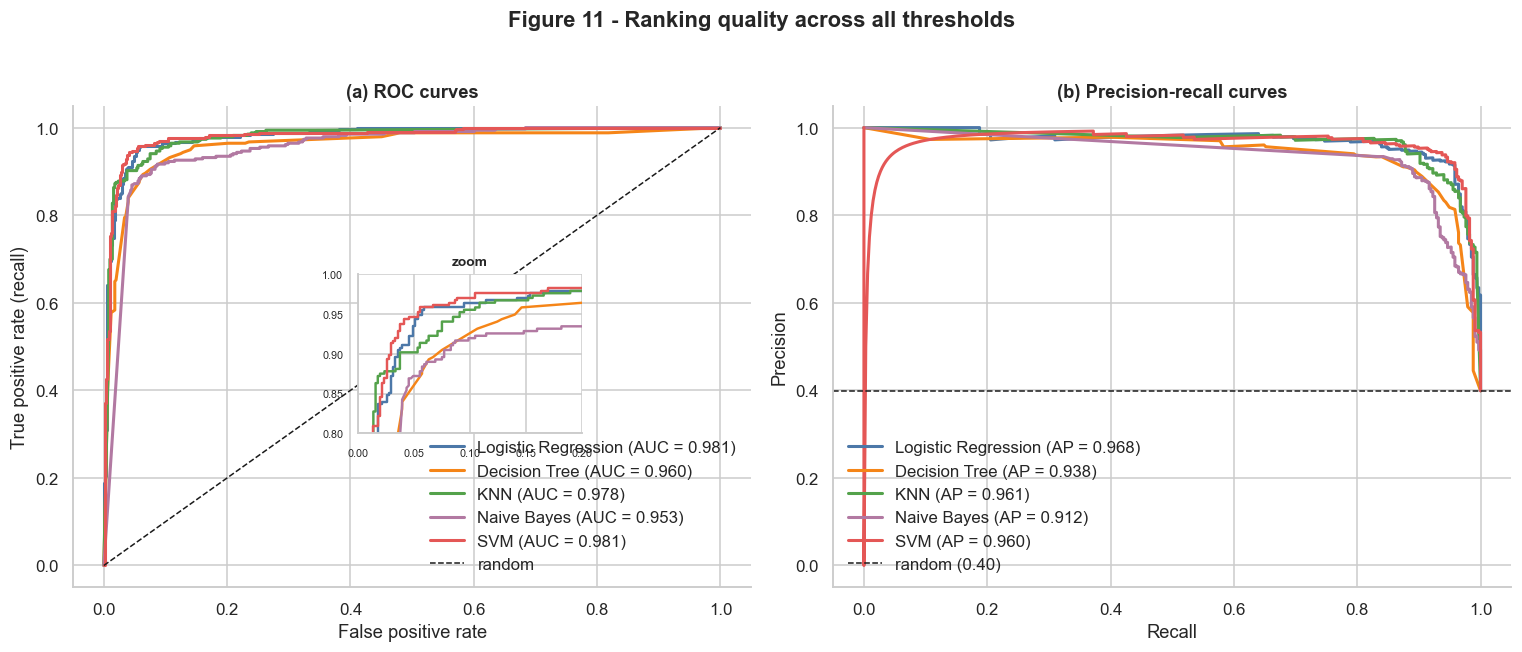

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.8))
base_rate = y_test.mean()

for name in trained:
    fpr, tpr, _ = roc_curve(y_test, probas[name])
    axes[0].plot(fpr, tpr, lw=2, color=MODEL_COLORS[name],
                 label=f"{name} (AUC = {roc_auc_score(y_test, probas[name]):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, probas[name])
    axes[1].plot(rec, prec, lw=2, color=MODEL_COLORS[name],
                 label=f"{name} (AP = {average_precision_score(y_test, probas[name]):.3f})")

axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="random")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate (recall)")
axes[0].set_title("(a) ROC curves")
axes[0].legend(loc="lower right")

axes[1].axhline(base_rate, ls="--", c="k", lw=1, label=f"random ({base_rate:.2f})")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("(b) Precision-recall curves")
axes[1].legend(loc="lower left")

# zoomed inset on the top-left of the ROC plot
ins = axes[0].inset_axes([0.42, 0.32, 0.33, 0.33])
for name in trained:
    fpr, tpr, _ = roc_curve(y_test, probas[name])
    ins.plot(fpr, tpr, lw=1.6, color=MODEL_COLORS[name])
ins.set_xlim(0, 0.2); ins.set_ylim(0.8, 1.0); ins.set_title("zoom", fontsize=9)
ins.tick_params(labelsize=7)

plt.suptitle("Figure 11 - Ranking quality across all thresholds", fontweight="bold", y=1.02)
plt.tight_layout(); save_fig(fig, "fig11_roc_pr"); plt.show()

## 9. Overfitting check: training vs test accuracy

**A note on KNN.** With `weights="distance"`, every training email is its own nearest neighbour at distance 0, so KNN scores about 100% on its training data *by construction*. Its fold-to-fold scores (Figure 8) are the honest measure, and they match its test score closely.

> **What this shows:** each model's accuracy on the data it learned from (filled dot) vs on the test emails it has never seen (hollow dot). The grey row is the Decision Tree *before* pruning, shown for comparison.
>
> **How to read it:** The longer the line between the two dots, the more the model memorised instead of learning general patterns. A short line means it generalises well.
>
> **Why it matters:** It shows which models overfit, and confirms that pruning fixed the Decision Tree.

,Train Accuracy,Test Accuracy,Gap (pp)
Logistic Regression,0.9397,0.9382,+0.15
Decision Tree,0.9492,0.9169,+3.23
KNN,0.9991,0.9311,+6.80
Naive Bayes,0.8388,0.8420,-0.32
SVM,0.9757,0.9525,+2.32
Decision Tree (before pruning),0.9991,0.9097,+8.94


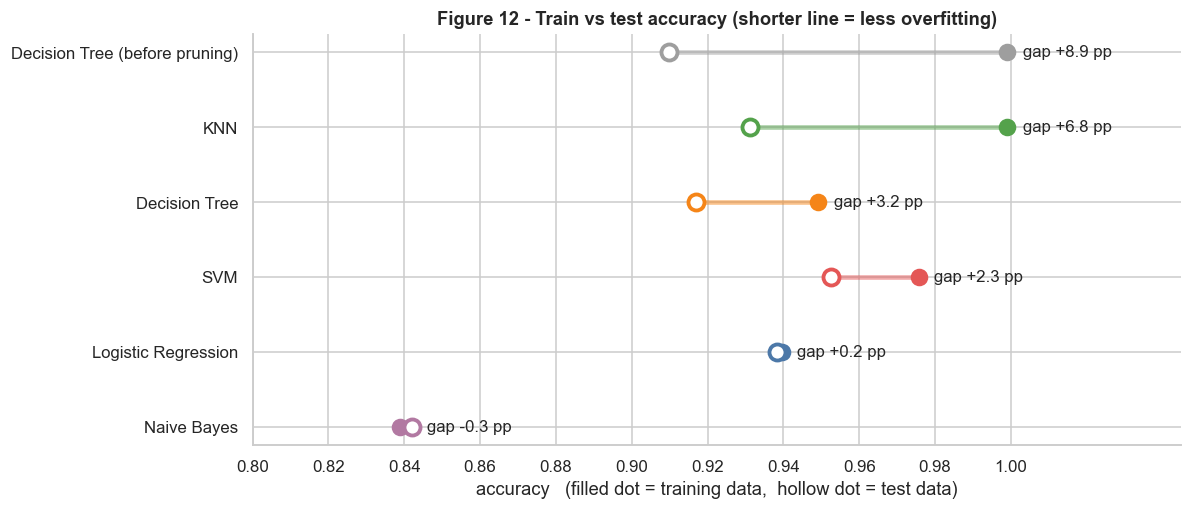

In [22]:
gap = pd.DataFrame({
    "Train Accuracy": {n: accuracy_score(y_train, m.predict(X_train)) for n, m in trained.items()},
    "Test Accuracy":  results["Accuracy"],
})
gap.loc["Decision Tree (before pruning)"] = [accuracy_score(y_train, dt_unpruned.predict(X_train)),
                                             dt_before_test["Accuracy"]]
gap["Gap (pp)"] = (gap["Train Accuracy"] - gap["Test Accuracy"]) * 100
display(gap.style.format({"Train Accuracy": "{:.4f}", "Test Accuracy": "{:.4f}", "Gap (pp)": "{:+.2f}"})
        .bar(subset=["Gap (pp)"], color="#E45756", align="zero"))

fig, ax = plt.subplots(figsize=(11, 4.8))
order = gap.sort_values("Gap (pp)").index
for i, n in enumerate(order):
    col = MODEL_COLORS.get(n, "#9E9E9E")
    tr, te = gap.loc[n, "Train Accuracy"], gap.loc[n, "Test Accuracy"]
    ax.plot([te, tr], [i, i], c=col, lw=3, alpha=0.5, zorder=1)
    ax.scatter(tr, i, s=110, c=col, zorder=2)
    ax.scatter(te, i, s=110, c="white", edgecolors=col, linewidths=2.5, zorder=3)
    ax.text(max(tr, te) + 0.004, i, f"gap {gap.loc[n, 'Gap (pp)']:+.1f} pp", va="center", fontsize=11)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=11)
ax.set_xlabel("accuracy   (filled dot = training data,  hollow dot = test data)")
lo = gap.values[:, :2].min() - 0.02
ax.set_xlim(lo, 1.045)
ax.set_xticks(np.arange(np.floor(lo * 50) / 50, 1.0001, 0.02))
ax.set_title("Figure 12 - Train vs test accuracy (shorter line = less overfitting)")
plt.tight_layout(); save_fig(fig, "fig12_train_test_gap"); plt.show()

## 10. How confident is each model?

Each model gives every email a **spam score** between 0 and 1. By default, a score above 0.5 means "spam".

> **What this shows:** for each model, where it placed the 506 legitimate emails (teal) and the 336 spam emails (red) on that 0-to-1 spam score.
>
> **How to read it:** A good model pushes teal to the **left** (near 0) and red to the **right** (near 1), with little overlap. Teal bars to the right of the dashed 0.5 line are good emails wrongly blocked. Red bars to the left are spam that got through.
>
> **Why it matters:** This explains *why* a model makes its mistakes. In particular, it shows that Naive Bayes is over-confident: it pushes many legitimate emails all the way to a score near 1, which causes its 115 false alarms.

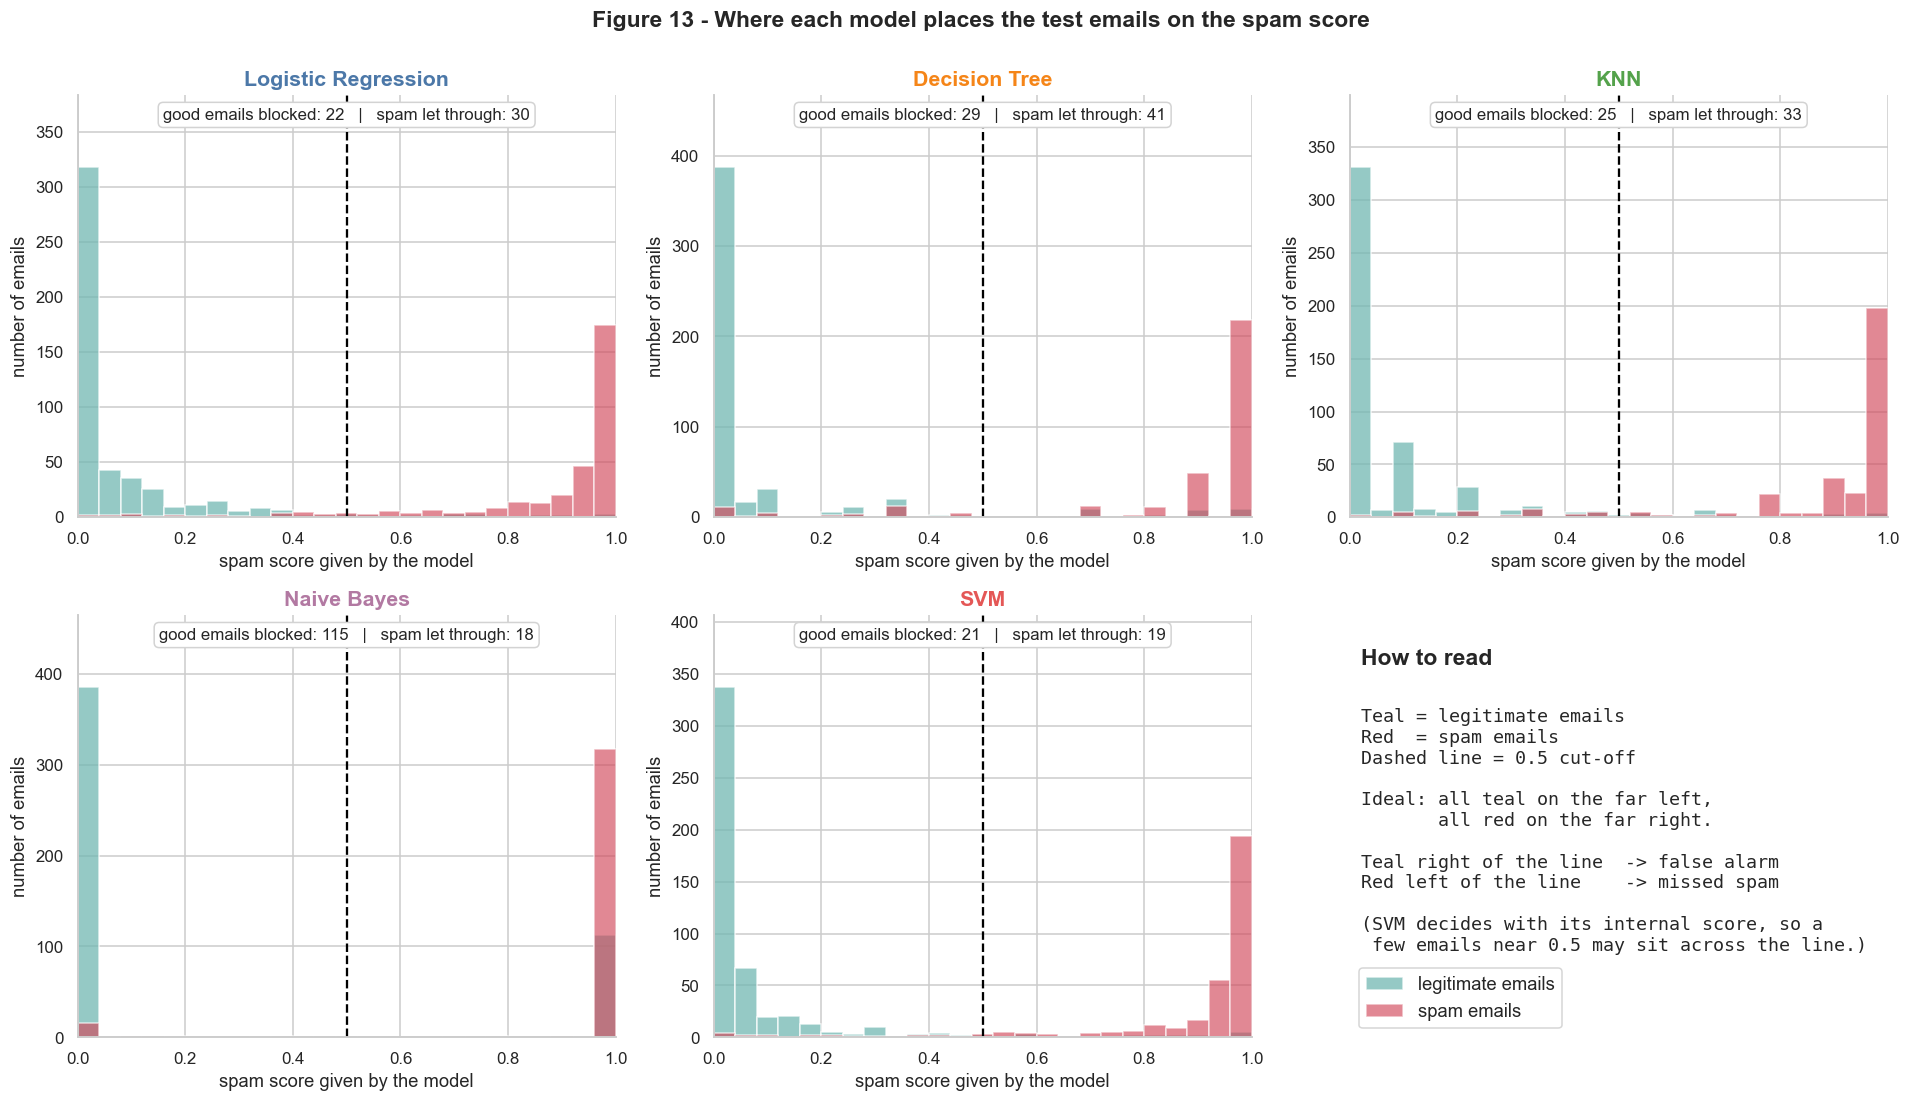

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()
bins = np.linspace(0, 1, 26)

for ax, name in zip(axes, trained):
    p = probas[name]
    ax.hist(p[y_test.values == 0], bins=bins, color=CLASS_COLORS["Legitimate"], alpha=0.75,
            label="legitimate emails")
    ax.hist(p[y_test.values == 1], bins=bins, color=CLASS_COLORS["Spam"], alpha=0.65,
            label="spam emails")
    ax.axvline(0.5, ls="--", c="black", lw=1.5)
    tn, fp, fn, tp = cms[name].ravel()
    ax.text(0.5, 0.97, f"good emails blocked: {fp}   |   spam let through: {fn}",
            transform=ax.transAxes, ha="center", va="top", fontsize=11,
            bbox=dict(boxstyle="round", fc="white", ec="lightgrey"))
    ax.set_title(name, color=MODEL_COLORS[name], fontsize=14)
    ax.set_xlabel("spam score given by the model")
    ax.set_ylabel("number of emails")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, ax.get_ylim()[1] * 1.15)

handles, labels_ = axes[0].get_legend_handles_labels()
axes[5].axis("off")
axes[5].legend(handles, labels_, loc="lower left", fontsize=12, frameon=True)
axes[5].text(0.02, 0.92, "How to read", fontsize=15, fontweight="bold", va="top")
axes[5].text(0.02, 0.78,
             "Teal = legitimate emails\nRed  = spam emails\nDashed line = 0.5 cut-off\n\n"
             "Ideal: all teal on the far left,\n       all red on the far right.\n\n"
             "Teal right of the line  -> false alarm\nRed left of the line    -> missed spam\n\n"
             "(SVM decides with its internal score, so a\n few emails near 0.5 may sit across the line.)",
             fontsize=12, va="top", family="monospace")
plt.suptitle("Figure 13 - Where each model places the test emails on the spam score",
             fontweight="bold", fontsize=15, y=1.0)
plt.tight_layout(); save_fig(fig, "fig13_model_confidence"); plt.show()

## 11. Interpretability: what drives the predictions?

Each model is inspected with the tool that suits it:
- **Logistic Regression** is read through its coefficients. These are on the log-scaled, standardised features, so they can be compared with each other.
- **The Decision Tree** is read through its impurity-based feature importances and a plot of its top splits.
- **SVM (RBF)** has no coefficients, so I use **permutation importance**. Each feature is shuffled in turn on the test set, and the resulting drop in F1 is measured.

> **What this shows:** which features each model relies on most.
>
> **How to read it:** (a) Logistic Regression: a red bar to the right pushes an email towards spam; a teal bar to the left pushes it towards legitimate. Longer means stronger. (b) Decision Tree: longer bars are features the tree splits on more usefully. (c) SVM: how much F1 drops when a feature is randomly shuffled. A bigger drop means the model depends on that feature more.
>
> **Why it matters:** It checks that the models learned sensible signals, such as `$`, `!`, `remove` and capital letters for spam, and it reveals dataset quirks, such as `hp` and `george` for legitimate email.

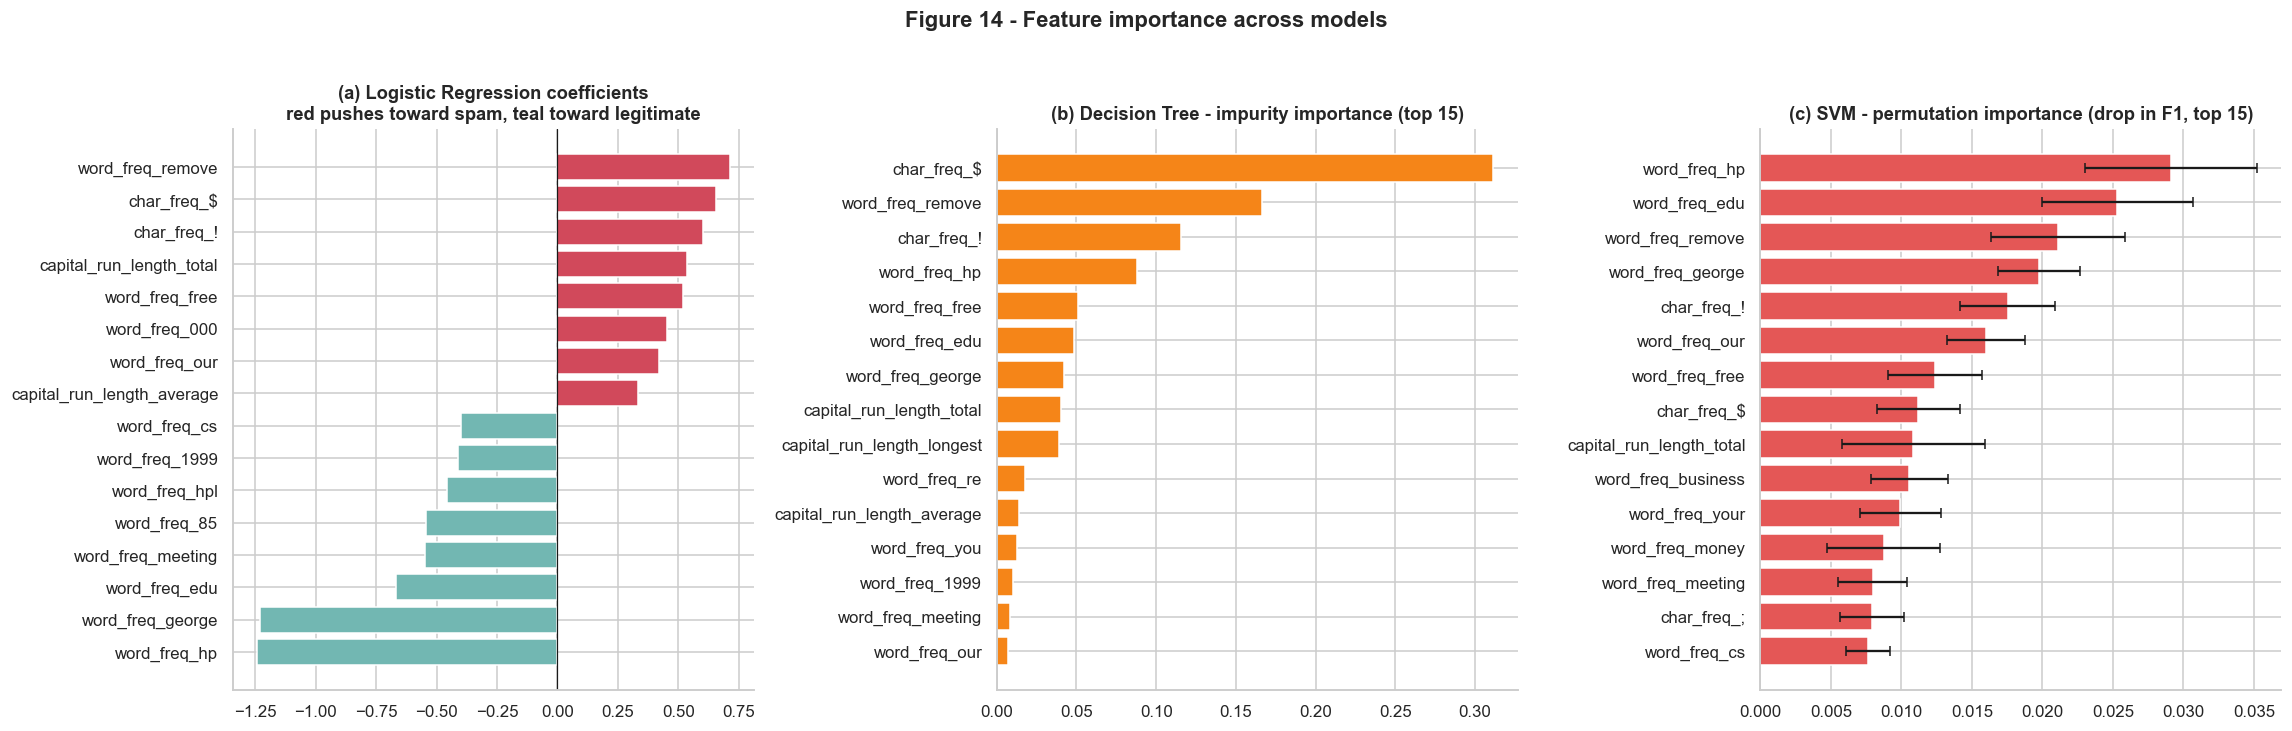

Decision Tree size: depth = 15, leaves = 46


In [24]:
lr_coef = pd.Series(trained["Logistic Regression"].named_steps["model"].coef_[0], index=FEATURES)
lr_top = pd.concat([lr_coef.sort_values().head(8), lr_coef.sort_values().tail(8)])

dt_imp = pd.Series(trained["Decision Tree"].named_steps["model"].feature_importances_,
                   index=FEATURES).sort_values().tail(15)

perm = permutation_importance(trained["SVM"], X_test, y_test, scoring="f1",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
svm_imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values().tail(15)
svm_err = pd.Series(perm.importances_std, index=FEATURES)[svm_imp.index]

fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))
axes[0].barh(lr_top.index, lr_top.values,
             color=[CLASS_COLORS["Spam"] if v > 0 else CLASS_COLORS["Legitimate"] for v in lr_top.values])
axes[0].axvline(0, c="k", lw=0.8)
axes[0].set_title("(a) Logistic Regression coefficients\nred pushes toward spam, teal toward legitimate")

axes[1].barh(dt_imp.index, dt_imp.values, color=MODEL_COLORS["Decision Tree"])
axes[1].set_title("(b) Decision Tree - impurity importance (top 15)")

axes[2].barh(svm_imp.index, svm_imp.values, xerr=svm_err.values, color=MODEL_COLORS["SVM"], capsize=3)
axes[2].set_title("(c) SVM - permutation importance (drop in F1, top 15)")

plt.suptitle("Figure 14 - Feature importance across models", fontweight="bold", y=1.02)
plt.tight_layout(); save_fig(fig, "fig14_feature_importance"); plt.show()

tree = trained["Decision Tree"].named_steps["model"]
print(f"Decision Tree size: depth = {tree.get_depth()}, leaves = {tree.get_n_leaves()}")

> **What this shows:** the first three levels of questions the pruned Decision Tree asks about an email.
>
> **How to read it:** Start at the top box. If the condition is true, go left; otherwise go right. `samples` is the share of training emails reaching that box, `value` is the [legitimate, spam] split there, and the colour shows the majority class (orange = legitimate, blue = spam).
>
> **Why it matters:** Decision trees are the easiest model to explain to a non-technical person, and this shows the rules it actually learned.

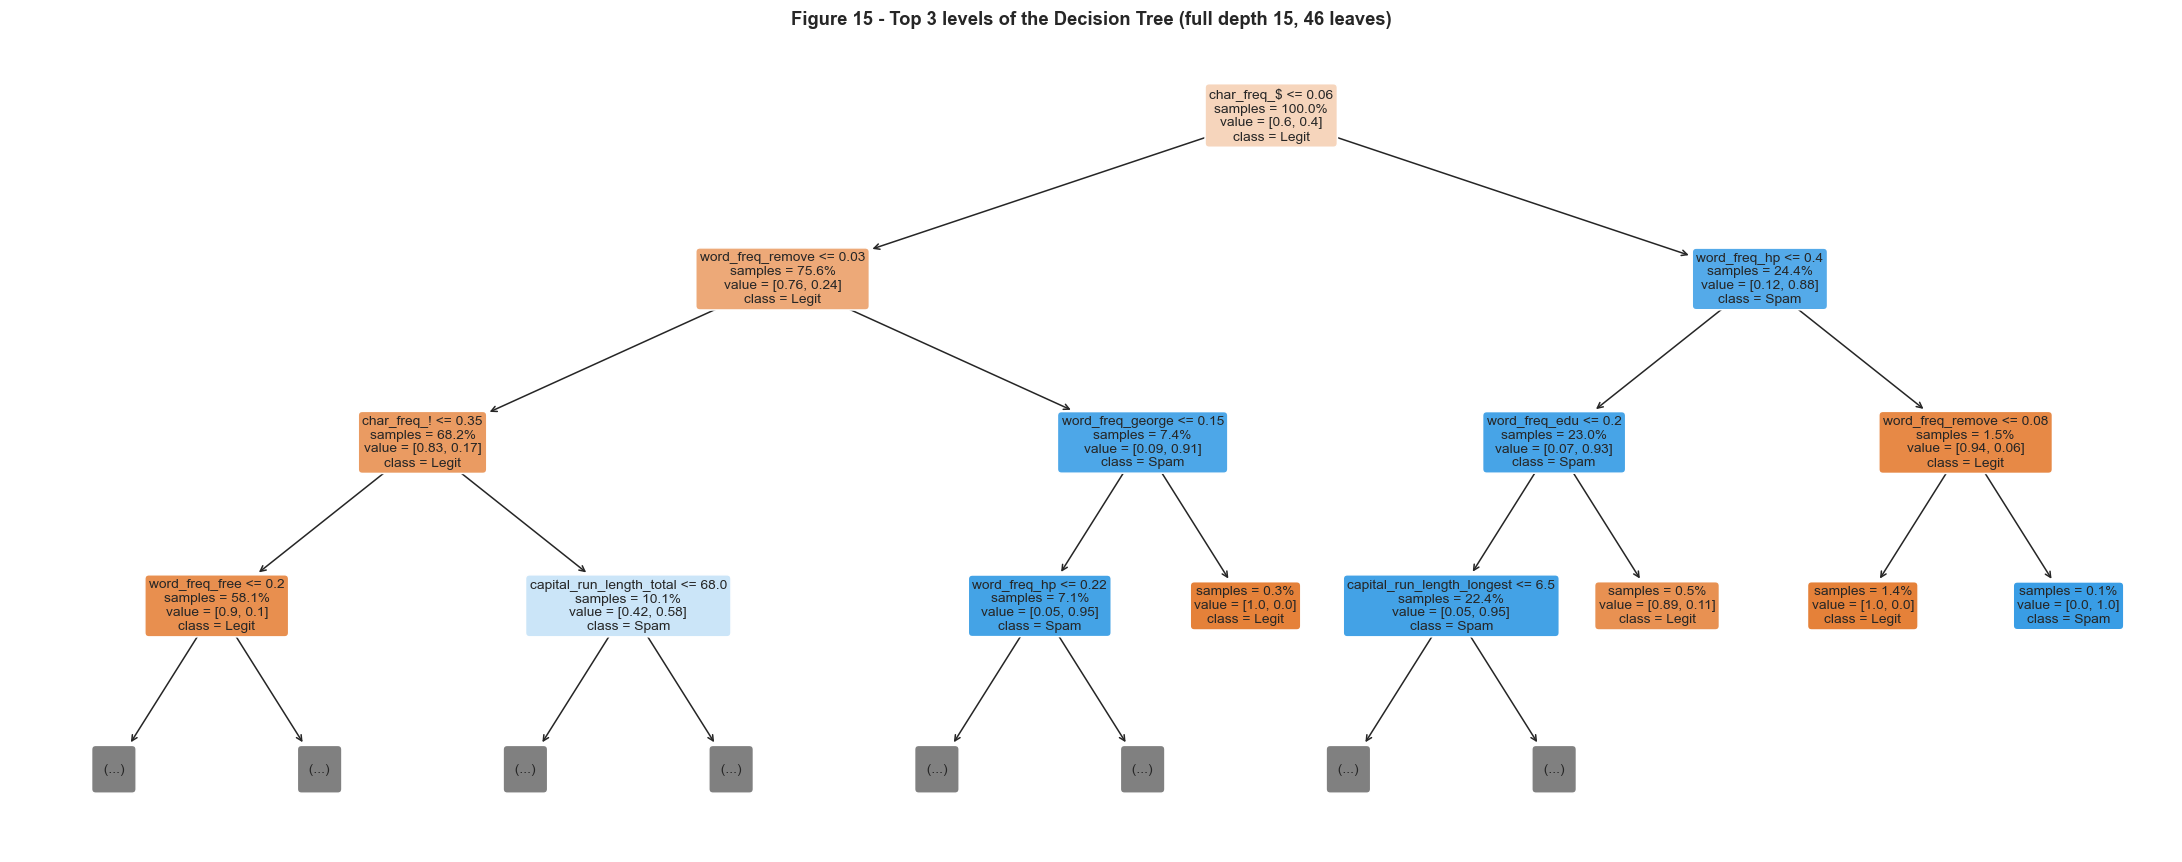

In [25]:
fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(tree, max_depth=3, feature_names=FEATURES, class_names=["Legit", "Spam"],
          filled=True, rounded=True, impurity=False, proportion=True, precision=2, fontsize=9, ax=ax)
ax.set_title(f"Figure 15 - Top 3 levels of the Decision Tree (full depth {tree.get_depth()}, "
             f"{tree.get_n_leaves()} leaves)", fontweight="bold")
plt.tight_layout(); save_fig(fig, "fig15_tree_top_levels"); plt.show()

## 12. Is the winner's lead real, or just luck?

SVM made fewer mistakes than Logistic Regression on our 842 test emails. But with a different set of test emails, could the order flip? **McNemar's test** answers this.

**The idea in plain words.** Ignore the emails that *both* models got right, and the emails that *both* got wrong, because they tell us nothing about which model is better. Look only at the emails where the models **disagree**:

- emails SVM got right and the other model got wrong, and
- emails the other model got right and SVM got wrong.

If the two models were equally good, these two counts would be roughly equal, like a fair coin toss. If one count is much bigger, the **p-value** tells us how likely a gap that big would be by pure chance. **p < 0.05** means "less than a 5% chance this is luck", so we call the difference **real (statistically significant)**.

> **What this shows:** for each model compared with SVM, the emails where only one of the two got the answer right.
>
> **How to read it:** The red bar (right) counts emails only SVM got right. The coloured bar (left) counts emails only the other model got right. The label gives the p-value and the verdict.
>
> **Why it matters:** It turns "SVM scored a bit higher" into "SVM is genuinely better, and not because of the particular test emails we happened to pick".

,Model A,Model B,Only A right,Only B right,p-value,Verdict (5% level)
0,Logistic Regression,Decision Tree,37,19,0.0231,real difference
1,Logistic Regression,KNN,20,14,0.3912,could be chance
2,Logistic Regression,Naive Bayes,105,24,0.0000,real difference
3,Logistic Regression,SVM,8,20,0.0376,real difference
4,Decision Tree,KNN,31,43,0.2010,could be chance
5,Decision Tree,Naive Bayes,108,45,0.0000,real difference
6,Decision Tree,SVM,15,45,0.0002,real difference
7,KNN,Naive Bayes,105,30,0.0000,real difference
8,KNN,SVM,6,24,0.0019,real difference
9,Naive Bayes,SVM,18,111,0.0000,real difference


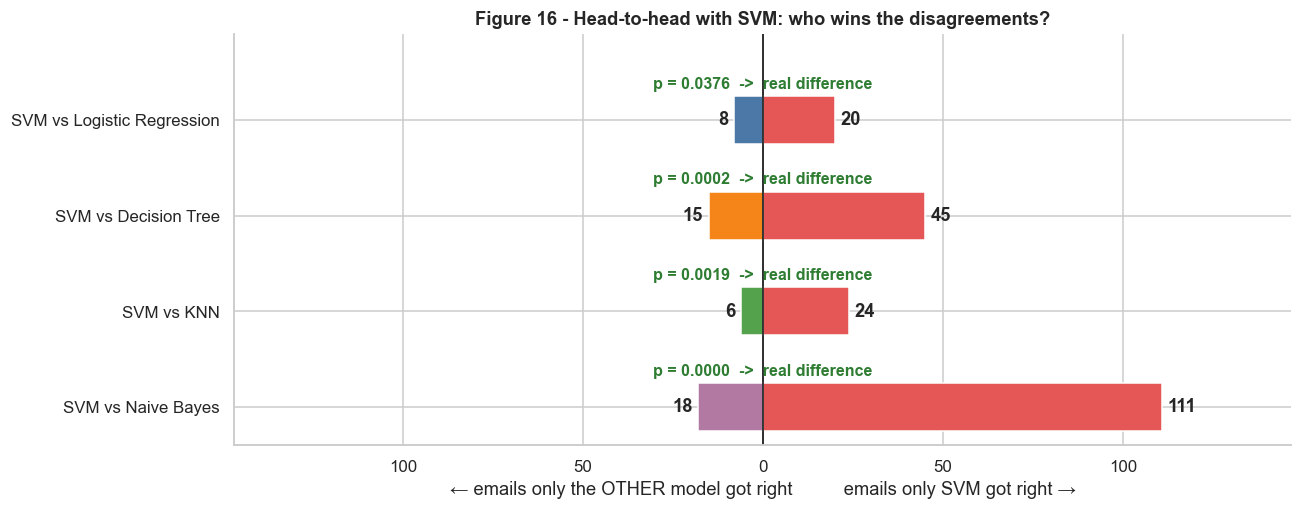

In [26]:
names = list(trained)
correct = {n: (preds[n] == y_test.values) for n in names}

def mcnemar(a, b):
    a_only = int(np.sum(correct[a] & ~correct[b]))   # a right, b wrong
    b_only = int(np.sum(~correct[a] & correct[b]))   # a wrong, b right
    if a_only + b_only == 0:
        return a_only, b_only, 1.0
    stat = (abs(a_only - b_only) - 1) ** 2 / (a_only + b_only)
    return a_only, b_only, float(chi2.sf(stat, df=1))

def verdict(p):
    return "real difference" if p < 0.05 else "could be chance"

rows = []
for i, a in enumerate(names):
    for b in names[i + 1:]:
        a_only, b_only, p = mcnemar(a, b)
        rows.append({"Model A": a, "Model B": b, "Only A right": a_only, "Only B right": b_only,
                     "p-value": round(p, 4), "Verdict (5% level)": verdict(p)})
mc_table = pd.DataFrame(rows)
display(mc_table.style.apply(
    lambda r: ["background-color:#d9f2d9" if r["Verdict (5% level)"] == "real difference"
               else "background-color:#fbe3e3"] * len(r), axis=1)
    .format({"p-value": "{:.4f}"}).set_caption("All pairs of models (green = real difference)"))

others = [n for n in names if n != "SVM"]
fig, ax = plt.subplots(figsize=(12, 4.8))
for i, n in enumerate(others):
    svm_only, other_only, p = mcnemar("SVM", n)
    ax.barh(i, svm_only, height=0.5, color=MODEL_COLORS["SVM"])
    ax.barh(i, -other_only, height=0.5, color=MODEL_COLORS[n])
    ax.text(svm_only + 1.5, i, f"{svm_only}", va="center", fontweight="bold")
    ax.text(-other_only - 1.5, i, f"{other_only}", va="center", ha="right", fontweight="bold")
    ax.text(0, i - 0.3, f"p = {p:.4f}  ->  {verdict(p)}", ha="center", va="bottom", fontsize=10.5,
            fontweight="bold", color="#2E7D32" if p < 0.05 else "#C62828")
ax.axvline(0, c="black", lw=1)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{abs(v):.0f}"))
ax.set_yticks(range(len(others))); ax.set_yticklabels([f"SVM vs {n}" for n in others], fontsize=11)
ax.set_xlabel("← emails only the OTHER model got right          emails only SVM got right →")
lim = max(abs(v) for v in ax.get_xlim())
ax.set_xlim(-lim * 1.25, lim * 1.25)
ax.set_ylim(len(others) - 0.6, -0.9)
ax.set_title("Figure 16 - Head-to-head with SVM: who wins the disagreements?")
plt.tight_layout(); save_fig(fig, "fig16_mcnemar_vs_svm"); plt.show()

## 13. Computational cost

A model that is slightly more accurate but much slower or larger is not automatically the best choice for deployment. Here I measure the final fit time, the time to score 1,000 emails, and the size of the saved file.

> **What this shows:** (1) how long each model takes to train, (2) how long it takes to score 1,000 emails, and (3) how big the saved model file is.
>
> **How to read it:** Shorter bars are cheaper. The x-axis is on a log scale, so each grid step is 10 times bigger than the one before.
>
> **Why it matters:** For a real spam filter that checks millions of emails, a model that is slightly less accurate but 100 times faster can be the better choice.

,Fit time (s),Predict 1k emails (ms),Model size (KB),Test F1
Logistic Regression,0.056,3.6,6,0.9217
Decision Tree,0.054,2.3,9,0.8939
KNN,0.022,82.3,"1,519",0.9127
Naive Bayes,0.026,4.5,7,0.8270
SVM,1.593,160.4,400,0.9407


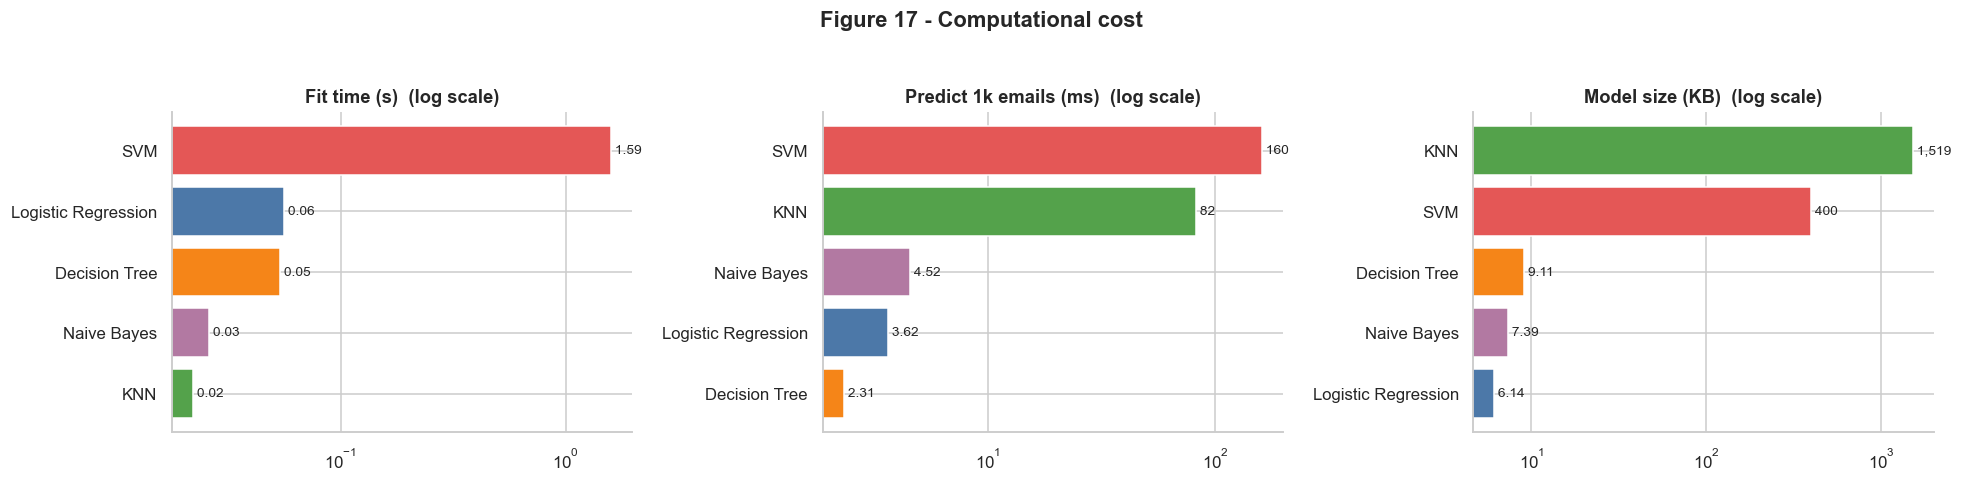

In [27]:
cost = {}
for name, m in trained.items():
    reps = []
    for _ in range(5):
        t0 = time.perf_counter(); m.predict_proba(X_test); reps.append(time.perf_counter() - t0)
    buf = io.BytesIO(); joblib.dump(m, buf)
    cost[name] = {"Fit time (s)": float(search_df.loc[name, "Final fit time (s)"]),
                  "Predict 1k emails (ms)": np.median(reps) / len(X_test) * 1000 * 1000,
                  "Model size (KB)": buf.getbuffer().nbytes / 1024,
                  "Test F1": results.loc[name, "F1"]}
cost = pd.DataFrame(cost).T
display(cost.style.format({"Fit time (s)": "{:.3f}", "Predict 1k emails (ms)": "{:.1f}",
                           "Model size (KB)": "{:,.0f}", "Test F1": "{:.4f}"}))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
for ax, col in zip(axes, ["Fit time (s)", "Predict 1k emails (ms)", "Model size (KB)"]):
    s = cost[col].sort_values()
    ax.barh(s.index, s.values, color=[MODEL_COLORS[n] for n in s.index])
    ax.set_xscale("log"); ax.set_title(col + "  (log scale)")
    for i, v in enumerate(s.values):
        ax.text(v, i, f" {v:,.2f}" if v < 10 else f" {v:,.0f}", va="center", fontsize=9)
plt.suptitle("Figure 17 - Computational cost", fontweight="bold", y=1.04)
plt.tight_layout(); save_fig(fig, "fig17_cost"); plt.show()

## 14. Error analysis: which emails are hard?

> **What this shows:** for every test email, how many of the five models got it wrong.
>
> **How to read it:** The green bar counts emails that every model got right. The red bars on the right count emails that most or all models got wrong.
>
> **Why it matters:** Emails that fool every model are probably genuinely ambiguous, such as a real newsletter that looks like spam. No model choice would fix those; it would take better features.

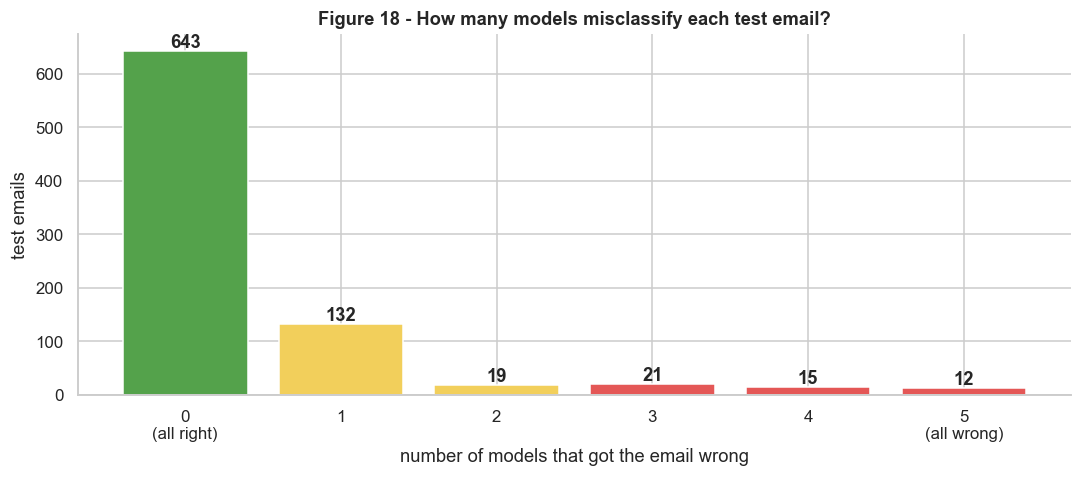

Emails misclassified by all 5 models: 12  |  by none: 643 of 842


In [28]:
wrong_count = sum((~correct[n]).astype(int) for n in names)
dist = pd.Series(wrong_count).value_counts().reindex(range(6), fill_value=0)

fig, ax = plt.subplots(figsize=(10, 4.5))
cols = ["#54A24B", "#F2CF5B", "#F2CF5B", "#E45756", "#E45756", "#E45756"]
ax.bar(dist.index, dist.values, color=cols)
for i, v in enumerate(dist.values):
    ax.text(i, v + max(dist.values) * 0.01, f"{v}", ha="center", fontweight="bold")
ax.set_xticks(range(6))
ax.set_xticklabels(["0\n(all right)", "1", "2", "3", "4", "5\n(all wrong)"])
ax.set_xlabel("number of models that got the email wrong")
ax.set_ylabel("test emails")
ax.set_title("Figure 18 - How many models misclassify each test email?")
plt.tight_layout(); save_fig(fig, "fig18_hard_emails"); plt.show()

print(f"Emails misclassified by all 5 models: {dist[5]}  |  by none: {dist[0]} of {len(y_test)}")

## 15. Evidence summary

One table with every number the observations rely on.

In [29]:
cv_f1_mean = cv_folds.groupby("Model")["F1"].mean()
evidence = pd.DataFrame({
    "Test F1":           results["F1"],
    "Test MCC":          results["MCC"],
    "AUC":               results["AUC"],
    "Balanced accuracy": {n: balanced_accuracy_score(y_test, preds[n]) for n in names},
    "CV F1 (5 folds)":   cv_f1_mean,
    "Train-test gap pp": gap.loc[names, "Gap (pp)"],
    "False alarms":      err_table["False alarms (good -> spam)"],
    "Missed spam":       err_table["Missed spam (spam -> inbox)"],
    "Total errors":      err_table["Total errors"],
}).loc[names]
evidence["AUC - BalAcc"] = evidence["AUC"] - evidence["Balanced accuracy"]
display(evidence.style.format("{:.4f}", subset=["Test F1", "Test MCC", "AUC", "Balanced accuracy",
                                                 "CV F1 (5 folds)", "AUC - BalAcc"])
        .format("{:+.2f}", subset=["Train-test gap pp"])
        .background_gradient(cmap="Greens", subset=["Test F1", "Test MCC"])
        .background_gradient(cmap="Reds", subset=["Total errors", "Train-test gap pp"]))

,Test F1,Test MCC,AUC,Balanced accuracy,CV F1 (5 folds),Train-test gap pp,False alarms,Missed spam,Total errors,AUC - BalAcc
Logistic Regression,0.9217,0.8709,0.9809,0.9336,0.9154,+0.15,22,30,52,0.0473
Decision Tree,0.8939,0.8260,0.9600,0.9103,0.8953,+3.23,29,41,70,0.0497
KNN,0.9127,0.8560,0.9782,0.9262,0.9141,+6.80,25,33,58,0.0520
Naive Bayes,0.8270,0.7046,0.9533,0.8596,0.8173,-0.32,115,18,133,0.0937
SVM,0.9407,0.9011,0.9807,0.9510,0.9300,+2.32,21,19,40,0.0297


## 16. Save models and artefacts

Each fitted pipeline, including its preprocessing, is saved to `model/`. The Streamlit app loads these files and never retrains.

In [30]:
os.makedirs("model", exist_ok=True)
file_names = {
    "Logistic Regression": "logistic_regression.pkl",
    "Decision Tree":       "decision_tree.pkl",
    "KNN":                 "knn.pkl",
    "Naive Bayes":         "naive_bayes.pkl",
    "SVM":                 "svm.pkl",
}
for name, m in trained.items():
    path = os.path.join("model", file_names[name])
    joblib.dump(m, path)
    print(f"Saved {name:20s} -> {path} ({os.path.getsize(path) / 1024:,.0f} KB)")

metadata = {
    "dataset": "UCI Spambase",
    "features": FEATURES,
    "target": TARGET,
    "class_labels": {str(k): v for k, v in CLASS_LABELS.items()},
    "model_files": file_names,
    "sklearn_version": sklearn.__version__,
    "best_params": {n: str(search_df.loc[n, "Best parameters"]) for n in names},
}
with open(os.path.join("model", "metadata.json"), "w") as f:
    json.dump(metadata, f, indent=2)

results.to_csv(os.path.join("model", "model_comparison.csv"))
print("\nSaved model/metadata.json and model/model_comparison.csv")
print(f"Saved {len(list(FIG_DIR.glob('*.png')))} figures to {FIG_DIR}/")

# Training-time evidence for the Streamlit app's "final model" panel
final_model = cv_f1_mean.idxmax()          # chosen by cross-validation, then confirmed on the test set
training_summary = {
    "final_model": final_model,
    "selection_rule": "highest mean 5-fold cross-validation F1 on the training set",
    "n_train": int(len(y_train)),
    "cv_folds": int(cv.get_n_splits()),
    "cv": cv_numeric,
    "train_accuracy": {n: float(gap.loc[n, "Train Accuracy"]) for n in names},
    "best_params": {n: str(search_df.loc[n, "Best parameters"]) for n in names},
    "pruning": {"ccp_alpha": chosen_alpha,
                "leaves_before": int(before_after.loc["Before pruning", "Leaves"]),
                "leaves_after": int(before_after.loc["After pruning", "Leaves"]),
                "cv_f1_before": float(before_after.loc["Before pruning", "CV F1"]),
                "cv_f1_after": float(before_after.loc["After pruning", "CV F1"])},
}
with open(os.path.join("model", "training_summary.json"), "w") as f:
    json.dump(training_summary, f, indent=2)
print(f"Saved model/training_summary.json (final model: {final_model})")

Saved Logistic Regression  -> model\logistic_regression.pkl (6 KB)
Saved Decision Tree        -> model\decision_tree.pkl (9 KB)
Saved KNN                  -> model\knn.pkl (1,519 KB)
Saved Naive Bayes          -> model\naive_bayes.pkl (7 KB)
Saved SVM                  -> model\svm.pkl (400 KB)

Saved model/metadata.json and model/model_comparison.csv
Saved 18 figures to figures/
Saved model/training_summary.json (final model: SVM)


In [31]:
# Sanity check: reload from disk exactly as the Streamlit app does
check = pd.read_csv("test_data.csv")
rows = []
for name, fname in file_names.items():
    loaded = joblib.load(os.path.join("model", fname))
    f1 = f1_score(check[TARGET], loaded.predict(check[FEATURES]))
    rows.append({"Model": name, "Reloaded F1": round(f1, 4), "Table F1": results.loc[name, "F1"],
                 "Match": "✅" if abs(f1 - results.loc[name, "F1"]) < 1e-4 else "❌"})
display(pd.DataFrame(rows).set_index("Model"))

,Reloaded F1,Table F1,Match
Model,,,
Logistic Regression,0.9217,0.9217,✅
Decision Tree,0.8939,0.8939,✅
KNN,0.9127,0.9127,✅
Naive Bayes,0.8270,0.8270,✅
SVM,0.9407,0.9407,✅


## 17. Observations

The observations below are filled in **from this run's numbers**, so the text always matches the tables and figures above. The same text is saved to `observations_for_readme.md`, ready to paste into the README.

In [32]:
# Builds the observations from this run's numbers and saves them for the README
R, E = results, evidence
LR, DT, KNN, NB, SVM = "Logistic Regression", "Decision Tree", "KNN", "Naive Bayes", "SVM"
n_legit, n_spam = int((y_test == 0).sum()), int(y_test.sum())
ordinal = {1: "1st", 2: "2nd", 3: "3rd", 4: "4th", 5: "5th"}

f1_order = R["F1"].sort_values(ascending=False).index.tolist()
cv_order = cv_f1_mean.sort_values(ascending=False).index.tolist()
f1_rank = {n: f1_order.index(n) + 1 for n in names}
best_by = {m: R[m].idxmax() for m in R.columns}

fa = lambda n: int(err_table.loc[n, "False alarms (good -> spam)"])
ms = lambda n: int(err_table.loc[n, "Missed spam (spam -> inbox)"])
te = lambda n: int(err_table.loc[n, "Total errors"])
gp = lambda n: float(gap.loc[n, "Gap (pp)"])
r  = lambda n, m: float(R.loc[n, m])
p_of = lambda a, b: mcnemar(a, b)[2]

# ---------- comparison table
cols = list(R.columns)
tbl = ["| ML Model Name | " + " | ".join(cols) + " |", "|---" * (len(cols) + 1) + "|"]
for n in names:
    label = "Support Vector Machine" if n == SVM else n
    cells = [f"**{r(n, m):.4f}**" if best_by[m] == n else f"{r(n, m):.4f}" for m in cols]
    tbl.append(f"| {label} | " + " | ".join(cells) + " |")
table_md = "\n".join(tbl)

# ---------- per-model observations
C_lr = search_df.loc[LR, "Best parameters"]["C"]
obs_lr = (f"Strong and the **most stable** model: Accuracy {r(LR,'Accuracy'):.4f}, F1 {r(LR,'F1'):.4f}, "
          f"MCC {r(LR,'MCC'):.4f}, and AUC {r(LR,'AUC'):.4f}"
          + (" (the **highest AUC** of all models)" if best_by["AUC"] == LR else "") + ". "
          f"Its train–test gap is only **{gp(LR):+.2f} pp**, because cross-validation chose strong regularisation "
          f"(C = {C_lr}). Of its {te(LR)} errors, {ms(LR)} are missed spam and {fa(LR)} are false alarms, so it leans "
          f"towards letting spam through. A straight-line boundary cannot combine several cues the way the SVM can.")

d0, l0 = int(before_after.loc["Before pruning", "Depth"]), int(before_after.loc["Before pruning", "Leaves"])
d1, l1 = int(before_after.loc["After pruning", "Depth"]), int(before_after.loc["After pruning", "Leaves"])
tr0 = gap.loc["Decision Tree (before pruning)", "Train Accuracy"]
ts0 = gap.loc["Decision Tree (before pruning)", "Test Accuracy"]
g0, g1 = gp("Decision Tree (before pruning)"), gp(DT)
f1_0, f1_1 = dt_before_test["F1"], r(DT, "F1")
if f1_1 - f1_0 > 0.002:
    f1_change = f"test F1 **improved** from {f1_0:.4f} to {f1_1:.4f}"
elif f1_1 - f1_0 < -0.002:
    f1_change = (f"test F1 dipped slightly from {f1_0:.4f} to {f1_1:.4f}, a small price for a much simpler "
                 f"tree that behaves more predictably on new emails")
else:
    f1_change = f"test F1 stayed about the same ({f1_0:.4f} → {f1_1:.4f}) with a much simpler tree"
obs_dt = (f"The unlimited tree first chosen by grid search (depth {d0}, {l0} leaves) **memorised** the training "
          f"data: {tr0:.2%} train vs {ts0:.2%} test accuracy, a **{g0:.1f} pp gap**, which is the clearest overfitting here. "
          f"**Fix: cost-complexity pruning** (ccp_alpha = {chosen_alpha:.5f}, chosen by 5-fold CV with the "
          f"one-standard-error rule) cut it to **{l1} leaves** ({1 - l1 / l0:.0%} smaller) and the gap to "
          f"**{g1:.1f} pp**, while {f1_change}. Even after pruning it ranks {ordinal[f1_rank[DT]]} of 5 on F1 "
          f"({te(DT)} errors: {fa(DT)} false alarms, {ms(DT)} missed spam). A single tree splits on one feature at a "
          f"time, which is a coarse way to combine 57 weak signals.")

knn_mb = cost.loc[KNN, "Model size (KB)"] / 1024
p_lr_knn = p_of(LR, KNN)
obs_knn = (f"A solid **middle performer**: F1 {r(KNN,'F1'):.4f}, MCC {r(KNN,'MCC'):.4f}, AUC {r(KNN,'AUC'):.4f}, "
           f"with {te(KNN)} errors ({ms(KNN)} missed spam, {fa(KNN)} false alarms). "
           + (f"Its test F1 is close to its CV F1 ({cv_f1_mean[KNN]:.4f}), so it generalised as predicted. "
              if abs(r(KNN, 'F1') - cv_f1_mean[KNN]) < 0.01 else
              f"Its CV F1 was {cv_f1_mean[KNN]:.4f}. ")
           + f"The ~100% training accuracy comes from "
           f"`weights=\"distance\"` (each training email is its own nearest neighbour), not from real overfitting. "
           + (f"Its difference from Logistic Regression is **not statistically significant** (McNemar p = {p_lr_knn:.3f}). "
              if p_lr_knn >= 0.05 else f"It is significantly behind Logistic Regression (McNemar p = {p_lr_knn:.3f}). ")
           + f"It is the heaviest model to deploy: it stores all {len(X_train):,} training emails (≈{knn_mb:.1f} MB) "
           f"and compares every new email against all of them.")

worst_by = {m: R[m].idxmin() for m in R.columns}
nb_low = [m for m in ["Accuracy", "F1", "MCC"] if worst_by[m] == NB]
nb_open = ("Lowest " + ", ".join(f"{m} ({r(NB, m):.4f})" for m in nb_low)) if nb_low else \
          f"Accuracy {r(NB,'Accuracy'):.4f}, F1 {r(NB,'F1'):.4f}, MCC {r(NB,'MCC'):.4f}"
obs_nb = (nb_open + ", yet "
          + ("the **highest Recall**" if best_by["Recall"] == NB else "a high Recall") + f" ({r(NB,'Recall'):.4f}). "
          f"It wrongly blocks **{fa(NB)} of {n_legit} legitimate emails ({fa(NB) / n_legit:.1%})**, giving precision "
          f"{r(NB,'Precision'):.4f}" + (", which is unacceptable for an email filter. " if fa(NB) / n_legit > 0.10 else ". ") + f"Its AUC ({r(NB,'AUC'):.4f}) is far above its "
          f"balanced accuracy ({E.loc[NB,'Balanced accuracy']:.4f}). It ranks emails reasonably, but its spam scores are "
          f"**over-confident**, pushing many genuine emails close to 1 (Figure 13). The cause is the independence "
          f"assumption: correlated features (Figure 5) are counted as separate evidence. It does not overfit "
          f"(gap {gp(NB):+.2f} pp); it **underfits**, meaning high bias from overly simple assumptions.")

svm_best = [m for m in cols if best_by[m] == SVM]
svm_fewest = te(SVM) == min(te(n) for n in names)
only_090 = r(SVM, "MCC") > 0.90 and all(r(n, "MCC") <= 0.90 for n in names if n != SVM)
obs_svm = (f"**Best on {len(svm_best)} of 6 metrics** ({', '.join(svm_best)})"
           + (f", with MCC {r(SVM,'MCC'):.4f}, the only MCC above 0.90" if only_090 else "") + ". "
           + (f"Its AUC ({r(SVM,'AUC'):.4f}) is within {R['AUC'].max() - r(SVM,'AUC'):.4f} of the best. "
              if best_by["AUC"] != SVM else "")
           + (f"It makes the **fewest errors ({te(SVM)})**" if svm_fewest else f"It makes {te(SVM)} errors")
           + f", split evenly between false alarms ({fa(SVM)}) and missed spam ({ms(SVM)}). The RBF kernel learns a "
           f"curved boundary that combines many cues at once. Its gap is moderate ({gp(SVM):+.1f} pp) and it also had "
           f"the best cross-validation F1 ({cv_f1_mean[SVM]:.4f}), so its lead is not luck on one split.")

runner = f1_order[1]
fewer = 1 - te(SVM) / te(runner)
p_all = {n: p_of(SVM, n) for n in names if n != SVM}
sig_all = all(p < 0.05 for p in p_all.values())
size_ratio = cost.loc[SVM, "Model size (KB)"] / cost.loc[LR, "Model size (KB)"]
obs_win = (f"**SVM (RBF kernel).** It makes **{fewer:.0%} fewer errors than the runner-up** "
           f"({te(SVM)} vs {te(runner)} for {runner}), ranks first on {', '.join(svm_best)}, and has the best CV score. "
           + ("McNemar's test shows its lead is **statistically significant against every other model** "
              f"(p = {p_all[LR]:.3f} vs Logistic Regression). " if sig_all else
              f"McNemar p-values against the others: " + ", ".join(f"{k} {v:.3f}" for k, v in p_all.items()) + ". ")
           + (f"**Logistic Regression is the practical runner-up**: almost the same AUC, a model file about "
              f"{size_ratio:.0f}× smaller, and coefficients that are easy to explain. It is a good choice if speed or "
              f"explainability matter more than the last {(r(SVM,'Accuracy') - r(LR,'Accuracy')) * 100:.1f} pp of accuracy."
              if runner == LR else ""))

obs_rows = [("Logistic Regression", obs_lr), ("Decision Tree", obs_dt), ("KNN", obs_knn),
            ("Naive Bayes", obs_nb), ("Support Vector Machine", obs_svm),
            ("**Overall winner for this dataset**", obs_win)]
obs_table = "| ML Model Name | Observation about model performance |\n|---|---|\n" + \
            "\n".join(f"| **{a}** | {b} |" if not a.startswith("**") else f"| {a} | {b} |" for a, b in obs_rows)

# ---------- detailed justification
w_lr, l_lr, p_lr = mcnemar(SVM, LR)
p_dt_knn = p_of(DT, KNN)
detail = f"""
**1. Ranking is consistent.** By test F1 the order is **{' > '.join(f1_order)}**. Five-fold cross-validation on the training data gives {'the **same** order' if cv_order == f1_order else 'almost the same order'} ({' > '.join(cv_order)}), and every test score falls inside its model's CV range (Figure 8). The ranking therefore reflects the models themselves, not this particular test split.

**2. Why the SVM wins.** Spam is signalled by many cues acting together, such as `$`, `!`, `remove`, `free` and long runs of capitals, while legitimate email is signalled by context words such as `hp` and `george` (Figures 3 and 14). An RBF kernel can learn combinations of these cues; Logistic Regression can only add up each feature separately. Both models *rank* emails almost equally well (AUC {r(SVM,'AUC'):.4f} vs {r(LR,'AUC'):.4f}, Figure 11). The SVM's advantage is in its *decisions*: on the emails where the two disagree, SVM is right {w_lr} times and LR is right {l_lr} times (McNemar p = {p_lr:.3f}, {verdict(p_lr)}, Figure 16).

**3. Overfitting and the fix.** The unpruned Decision Tree had the biggest train–test gap ({g0:.1f} pp). Pruning it to {l1} leaves cut the gap to {g1:.1f} pp (Figures 7 and 12). Logistic Regression ({gp(LR):+.2f} pp) and SVM ({gp(SVM):+.2f} pp) generalise well. Naive Bayes shows almost no gap ({gp(NB):+.2f} pp) but low scores on both sides, which is the signature of underfitting. KNN's apparent gap is an artefact of distance weighting, as explained in Section 9.

**4. Ranking well vs deciding well.** The gap between AUC and balanced accuracy shows how much ranking ability a model wastes at the 0.5 cut-off: {E.loc[NB,'AUC - BalAcc']:.3f} for Naive Bayes vs {E.loc[SVM,'AUC - BalAcc']:.3f} for SVM. Figure 13 shows why. Naive Bayes pushes many legitimate emails to a spam score near 1, past the cut-off, while the SVM keeps the two classes cleanly apart.

**5. Which mistakes matter.** For an email user, a false alarm (a real email lost in the spam folder) is usually worse than one spam reaching the inbox. SVM blocks {fa(SVM)} good emails ({fa(SVM) / n_legit:.1%}) and Logistic Regression {fa(LR)} ({fa(LR) / n_legit:.1%}), while Naive Bayes blocks {fa(NB)} ({fa(NB) / n_legit:.1%}), almost one in four (Figure 10). This is why recall alone is not used to judge the models.

**6. Why MCC is reported.** With a 60/40 class split, accuracy can look good for a lopsided model. Naive Bayes reaches {r(NB,'Accuracy'):.1%} accuracy but only {r(NB,'MCC'):.2f} MCC, while SVM reaches {r(SVM,'MCC'):.2f}. MCC uses all four confusion-matrix cells, so it exposes the difference.

**7. Preprocessing matters.** Most features are zero for most emails, and the non-zero values are heavily skewed (Figure 2). The `log1p` and scaling steps (Figure 6) are what make KNN, SVM and Logistic Regression competitive.

**8. Not every difference is real.** Logistic Regression vs KNN: McNemar p = {p_lr_knn:.3f} ({verdict(p_lr_knn)}). Decision Tree vs KNN: p = {p_dt_knn:.3f} ({verdict(p_dt_knn)}). Small gaps in the metrics table should not be over-interpreted.

**9. Limitations.** (i) The results come from a single stratified split; agreement with CV reduces, but does not remove, split luck. (ii) All models use their default cut-off; tuning it could change the precision/recall balance. (iii) Spambase's legitimate emails come from one HP Labs mailbox, so words like `hp` and `george` are strong "legitimate" signals that would not carry over to other users' mail.
""".strip()

observations_md = ("### Comparison table (test set)\n\n" + table_md +
                   "\n\n### Observations on each model\n\n" + obs_table +
                   "\n\n### Supporting evidence\n\n" + detail)
display(Markdown(observations_md))
with open("observations_for_readme.md", "w", encoding="utf-8") as f:
    f.write(observations_md)
print("\nSaved observations_for_readme.md")

### Comparison table (test set)

| ML Model Name | Accuracy | AUC | Precision | Recall | F1 | MCC |
|---|---|---|---|---|---|---|
| Logistic Regression | 0.9382 | **0.9809** | 0.9329 | 0.9107 | 0.9217 | 0.8709 |
| Decision Tree | 0.9169 | 0.9600 | 0.9105 | 0.8780 | 0.8939 | 0.8260 |
| KNN | 0.9311 | 0.9782 | 0.9238 | 0.9018 | 0.9127 | 0.8560 |
| Naive Bayes | 0.8420 | 0.9533 | 0.7344 | **0.9464** | 0.8270 | 0.7046 |
| Support Vector Machine | **0.9525** | 0.9807 | **0.9379** | 0.9435 | **0.9407** | **0.9011** |

### Observations on each model

| ML Model Name | Observation about model performance |
|---|---|
| **Logistic Regression** | Strong and the **most stable** model: Accuracy 0.9382, F1 0.9217, MCC 0.8709, and AUC 0.9809 (the **highest AUC** of all models). Its train–test gap is only **+0.15 pp**, because cross-validation chose strong regularisation (C = 0.1). Of its 52 errors, 30 are missed spam and 22 are false alarms, so it leans towards letting spam through. A straight-line boundary cannot combine several cues the way the SVM can. |
| **Decision Tree** | The unlimited tree first chosen by grid search (depth 27, 194 leaves) **memorised** the training data: 99.91% train vs 90.97% test accuracy, a **8.9 pp gap**, which is the clearest overfitting here. **Fix: cost-complexity pruning** (ccp_alpha = 0.00283, chosen by 5-fold CV with the one-standard-error rule) cut it to **46 leaves** (76% smaller) and the gap to **3.2 pp**, while test F1 **improved** from 0.8872 to 0.8939. Even after pruning it ranks 4th of 5 on F1 (70 errors: 29 false alarms, 41 missed spam). A single tree splits on one feature at a time, which is a coarse way to combine 57 weak signals. |
| **KNN** | A solid **middle performer**: F1 0.9127, MCC 0.8560, AUC 0.9782, with 58 errors (33 missed spam, 25 false alarms). Its test F1 is close to its CV F1 (0.9141), so it generalised as predicted. The ~100% training accuracy comes from `weights="distance"` (each training email is its own nearest neighbour), not from real overfitting. Its difference from Logistic Regression is **not statistically significant** (McNemar p = 0.391). It is the heaviest model to deploy: it stores all 3,368 training emails (≈1.5 MB) and compares every new email against all of them. |
| **Naive Bayes** | Lowest Accuracy (0.8420), F1 (0.8270), MCC (0.7046), yet the **highest Recall** (0.9464). It wrongly blocks **115 of 506 legitimate emails (22.7%)**, giving precision 0.7344, which is unacceptable for an email filter. Its AUC (0.9533) is far above its balanced accuracy (0.8596). It ranks emails reasonably, but its spam scores are **over-confident**, pushing many genuine emails close to 1 (Figure 13). The cause is the independence assumption: correlated features (Figure 5) are counted as separate evidence. It does not overfit (gap -0.32 pp); it **underfits**, meaning high bias from overly simple assumptions. |
| **Support Vector Machine** | **Best on 4 of 6 metrics** (Accuracy, Precision, F1, MCC), with MCC 0.9011, the only MCC above 0.90. Its AUC (0.9807) is within 0.0002 of the best. It makes the **fewest errors (40)**, split evenly between false alarms (21) and missed spam (19). The RBF kernel learns a curved boundary that combines many cues at once. Its gap is moderate (+2.3 pp) and it also had the best cross-validation F1 (0.9300), so its lead is not luck on one split. |
| **Overall winner for this dataset** | **SVM (RBF kernel).** It makes **23% fewer errors than the runner-up** (40 vs 52 for Logistic Regression), ranks first on Accuracy, Precision, F1, MCC, and has the best CV score. McNemar's test shows its lead is **statistically significant against every other model** (p = 0.038 vs Logistic Regression). **Logistic Regression is the practical runner-up**: almost the same AUC, a model file about 65× smaller, and coefficients that are easy to explain. It is a good choice if speed or explainability matter more than the last 1.4 pp of accuracy. |

### Supporting evidence

**1. Ranking is consistent.** By test F1 the order is **SVM > Logistic Regression > KNN > Decision Tree > Naive Bayes**. Five-fold cross-validation on the training data gives the **same** order (SVM > Logistic Regression > KNN > Decision Tree > Naive Bayes), and every test score falls inside its model's CV range (Figure 8). The ranking therefore reflects the models themselves, not this particular test split.

**2. Why the SVM wins.** Spam is signalled by many cues acting together, such as `$`, `!`, `remove`, `free` and long runs of capitals, while legitimate email is signalled by context words such as `hp` and `george` (Figures 3 and 14). An RBF kernel can learn combinations of these cues; Logistic Regression can only add up each feature separately. Both models *rank* emails almost equally well (AUC 0.9807 vs 0.9809, Figure 11). The SVM's advantage is in its *decisions*: on the emails where the two disagree, SVM is right 20 times and LR is right 8 times (McNemar p = 0.038, real difference, Figure 16).

**3. Overfitting and the fix.** The unpruned Decision Tree had the biggest train–test gap (8.9 pp). Pruning it to 46 leaves cut the gap to 3.2 pp (Figures 7 and 12). Logistic Regression (+0.15 pp) and SVM (+2.32 pp) generalise well. Naive Bayes shows almost no gap (-0.32 pp) but low scores on both sides, which is the signature of underfitting. KNN's apparent gap is an artefact of distance weighting, as explained in Section 9.

**4. Ranking well vs deciding well.** The gap between AUC and balanced accuracy shows how much ranking ability a model wastes at the 0.5 cut-off: 0.094 for Naive Bayes vs 0.030 for SVM. Figure 13 shows why. Naive Bayes pushes many legitimate emails to a spam score near 1, past the cut-off, while the SVM keeps the two classes cleanly apart.

**5. Which mistakes matter.** For an email user, a false alarm (a real email lost in the spam folder) is usually worse than one spam reaching the inbox. SVM blocks 21 good emails (4.2%) and Logistic Regression 22 (4.3%), while Naive Bayes blocks 115 (22.7%), almost one in four (Figure 10). This is why recall alone is not used to judge the models.

**6. Why MCC is reported.** With a 60/40 class split, accuracy can look good for a lopsided model. Naive Bayes reaches 84.2% accuracy but only 0.70 MCC, while SVM reaches 0.90. MCC uses all four confusion-matrix cells, so it exposes the difference.

**7. Preprocessing matters.** Most features are zero for most emails, and the non-zero values are heavily skewed (Figure 2). The `log1p` and scaling steps (Figure 6) are what make KNN, SVM and Logistic Regression competitive.

**8. Not every difference is real.** Logistic Regression vs KNN: McNemar p = 0.391 (could be chance). Decision Tree vs KNN: p = 0.201 (could be chance). Small gaps in the metrics table should not be over-interpreted.

**9. Limitations.** (i) The results come from a single stratified split; agreement with CV reduces, but does not remove, split luck. (ii) All models use their default cut-off; tuning it could change the precision/recall balance. (iii) Spambase's legitimate emails come from one HP Labs mailbox, so words like `hp` and `george` are strong "legitimate" signals that would not carry over to other users' mail.


Saved observations_for_readme.md
